# **Optimisation: NIH & Mendeley Top Performing Models**

- **NIH (adult) dataset:** EfficientNetB4
- **Mendeley (paediatric) dataset:** Xception and the Nuclear Ensemble

---
Knowledge distillation into MobileNetV2 students, with grid searches over the distillation settings, and re-evaluation of the Nuclear Ensemble with vote weights tuned on the validation images, for the original and INT8 base models. The TensorFlow Lite conversion of the quantised models is in the training notebooks `EfficientNetB4_NIH` and `Nuclear_Ensemble_Classifier_Mendeley`.

---

## **EfficientNetB4 NIH Dataset**

In [ ]:
import tensorflow as tf
import numpy as np
import os
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score

print("TensorFlow version:", tf.__version__)

# from google.colab import drive
# drive.mount('/content/drive')

TensorFlow version: 2.19.0
Mounted at /content/drive


In [ ]:
NIH_TRAIN_DIR = "/content/drive/MyDrive/NIH_processed/train"
NIH_TEST_DIR = "/content/drive/MyDrive/NIH_processed/test"
TEACHER_MODEL_PATH = "/content/drive/MyDrive/NIH_models/Results/EffNetB4_epoch_15.h5"
OUTPUT_DIR = "/content/drive/MyDrive/NIH_models/Knowledge_Distillation"
os.makedirs(OUTPUT_DIR, exist_ok=True)

BATCH_SIZE = 32
IMG_SIZE = (224, 224)
DISTILL_EPOCHS = 10
TEMPERATURE = 3
ALPHA = 0.7
SEED = 123

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Configuration set")

Configuration set


In [ ]:
print("Preparing datasets...")

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    NIH_TRAIN_DIR,
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset='training',
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    NIH_TRAIN_DIR,
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset='validation',
    shuffle=True,
    seed=SEED
)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    NIH_TEST_DIR,
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = test_ds.class_names
print(f"Class names: {class_names}")
print("Data preparation complete")

Preparing datasets...
Found 5320 files belonging to 2 classes.
Using 4256 files for training.
Found 5320 files belonging to 2 classes.
Using 1064 files for validation.
Found 1784 files belonging to 2 classes.
Class names: ['normal', 'pneumonia']
Data preparation complete


In [ ]:
def count_classes(directory):
    counts = {}
    for class_name in os.listdir(directory):
        class_path = os.path.join(directory, class_name)
        if os.path.isdir(class_path):
            counts[class_name] = len([f for f in os.listdir(class_path)
                                     if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
    return counts

train_counts = count_classes(NIH_TRAIN_DIR)
total = sum(train_counts.values())
class_weights = {i: total / (len(train_counts) * count)
                for i, count in enumerate(train_counts.values())}

print(f"Class weights: {class_weights}")

Class weights: {0: 2.1262989608313347, 1: 0.6537232735315802}


In [ ]:
print("Loading teacher model (EfficientNetB4)...")

from tensorflow.keras.applications import EfficientNetB4
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Rescaling, Input
from tensorflow.keras.models import Model

inputs = Input(shape=(224, 224, 3))
x = Rescaling(1.0 / 255)(inputs)
x = tf.keras.applications.efficientnet.preprocess_input(x * 255.0)

base_model = EfficientNetB4(include_top=False, weights='imagenet', input_tensor=x)
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(1, activation='sigmoid')(x)

teacher_model = Model(inputs=inputs, outputs=outputs)
teacher_model.load_weights(TEACHER_MODEL_PATH)
teacher_model.trainable = False

print("Teacher model loaded successfully")

Loading teacher model (EfficientNetB4)...
71686520/71686520 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Teacher model loaded successfully


In [ ]:
print("Creating student model (MobileNetV2)...")

from tensorflow.keras.applications import MobileNetV2

student_inputs = Input(shape=(224, 224, 3))
student_x = Rescaling(1.0 / 255)(student_inputs)
student_x = tf.keras.applications.mobilenet_v2.preprocess_input(student_x * 255.0)

student_base = MobileNetV2(include_top=False, weights='imagenet', input_tensor=student_x)
student_x = student_base.output
student_x = GlobalAveragePooling2D()(student_x)
student_x = Dense(128, activation='relu')(student_x)
student_x = Dropout(0.3)(student_x)
student_outputs = Dense(1, activation='sigmoid')(student_x)

student_model = Model(inputs=student_inputs, outputs=student_outputs)

print("Student model created successfully")

Creating student model (MobileNetV2)...


/tmp/ipython-input-1118734276.py:9: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  student_base = MobileNetV2(include_top=False, weights='imagenet', input_tensor=student_x)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Student model created successfully


In [ ]:
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1.0 - epsilon)

        bce = -y_true * tf.math.log(y_pred)
        focal_weight = alpha * tf.pow(1 - y_pred, gamma)
        loss = focal_weight * bce

        return tf.reduce_mean(loss)
    return focal_loss_fixed

class DistillationLoss:
    def __init__(self, temperature=4, alpha=0.5):
        self.temperature = temperature
        self.alpha = alpha
        self.focal_loss_fn = focal_loss(gamma=2.0, alpha=0.25)
        self.bce = tf.keras.losses.BinaryCrossentropy()

    def __call__(self, y_true, student_pred, teacher_pred):
        student_loss = self.focal_loss_fn(y_true, student_pred)

        teacher_soft = tf.nn.sigmoid(teacher_pred / self.temperature)
        student_soft = tf.nn.sigmoid(student_pred / self.temperature)

        distillation_loss = self.bce(teacher_soft, student_soft)

        total_loss = self.alpha * distillation_loss + (1 - self.alpha) * student_loss
        return total_loss

print("Distillation loss defined")

Distillation loss defined


In [ ]:
print("Starting distillation training...")

import gc
gc.collect()

BATCH_SIZE_TRAIN = 16
TEMPERATURE = 4
ALPHA = 0.5
DISTILL_EPOCHS = 15

optimizer = tf.keras.optimizers.Adam(learning_rate=5e-5)
distill_loss_fn = DistillationLoss(temperature=TEMPERATURE, alpha=ALPHA)

train_loss_metric = tf.keras.metrics.Mean()
train_acc_metric = tf.keras.metrics.BinaryAccuracy()
val_loss_metric = tf.keras.metrics.Mean()
val_acc_metric = tf.keras.metrics.BinaryAccuracy()

best_val_acc = 0.0
patience_counter = 0
patience = 5
best_weights = None

for epoch in range(DISTILL_EPOCHS):
    print(f"\nEpoch {epoch + 1}/{DISTILL_EPOCHS}")

    train_loss_metric.reset_state()
    train_acc_metric.reset_state()

    for images, labels in train_ds:
        # Apply class weights
        sample_weights = tf.where(labels == 0,
                                  class_weights[0],
                                  class_weights[1])

        teacher_predictions = teacher_model(images, training=False)

        with tf.GradientTape() as tape:
            student_predictions = student_model(images, training=True)
            loss = distill_loss_fn(labels, student_predictions, teacher_predictions)
            # Apply class weights to loss
            weighted_loss = loss * tf.reduce_mean(sample_weights)

        gradients = tape.gradient(weighted_loss, student_model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, student_model.trainable_variables))

        train_loss_metric.update_state(weighted_loss)
        train_acc_metric.update_state(labels, student_predictions)

    val_loss_metric.reset_state()
    val_acc_metric.reset_state()

    for images, labels in val_ds:
        teacher_predictions = teacher_model(images, training=False)
        student_predictions = student_model(images, training=False)

        val_loss = distill_loss_fn(labels, student_predictions, teacher_predictions)
        val_loss_metric.update_state(val_loss)
        val_acc_metric.update_state(labels, student_predictions)

    train_loss = train_loss_metric.result().numpy()
    train_acc = train_acc_metric.result().numpy()
    val_loss = val_loss_metric.result().numpy()
    val_acc = val_acc_metric.result().numpy()

    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0
        best_weights = student_model.get_weights()
        student_model.save(os.path.join(OUTPUT_DIR, "student_model_best.keras"))
        print(f"Saved best model")
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print("Early stopping triggered")
            break

if best_weights is not None:
    student_model.set_weights(best_weights)

print("Distillation training completed")

Starting distillation training...

Epoch 1/15
Train Loss: 0.6205, Train Acc: 0.2526
Val Loss: 0.3476, Val Acc: 0.2444
Saved best model

Epoch 2/15
Train Loss: 0.6196, Train Acc: 0.2984
Val Loss: 0.3474, Val Acc: 0.3365
Saved best model

Epoch 3/15
Train Loss: 0.6192, Train Acc: 0.3799
Val Loss: 0.3475, Val Acc: 0.3938
Saved best model

Epoch 4/15
Train Loss: 0.6187, Train Acc: 0.4746
Val Loss: 0.3476, Val Acc: 0.4765
Saved best model

Epoch 5/15
Train Loss: 0.6183, Train Acc: 0.5862
Val Loss: 0.3491, Val Acc: 0.6259
Saved best model

Epoch 6/15
Train Loss: 0.6182, Train Acc: 0.6205
Val Loss: 0.3474, Val Acc: 0.4680

Epoch 7/15
Train Loss: 0.6178, Train Acc: 0.7070
Val Loss: 0.3493, Val Acc: 0.6382
Saved best model

Epoch 8/15
Train Loss: 0.6179, Train Acc: 0.6995
Val Loss: 0.3517, Val Acc: 0.7124
Saved best model

Epoch 9/15
Train Loss: 0.6177, Train Acc: 0.7333
Val Loss: 0.3510, Val Acc: 0.7077

Epoch 10/15
Train Loss: 0.6175, Train Acc: 0.7662
Val Loss: 0.3478, Val Acc: 0.5141

Epoch

In [ ]:
print("Loading best student model...")

# Don't reload - just use the current student_model which already has best weights restored
# The model in memory is already the best one due to early stopping with restore_best_weights

# Save in Keras format (not HDF5)
student_model.save(os.path.join(OUTPUT_DIR, "student_model_final.keras"))
print(f"Student model saved to: {os.path.join(OUTPUT_DIR, 'student_model_final.keras')}")

student_size_mb = os.path.getsize(os.path.join(OUTPUT_DIR, "student_model_final.keras")) / (1024 * 1024)
print(f"Student model size: {student_size_mb:.2f} MB")

Loading best student model...
Student model saved to: /content/drive/MyDrive/NIH_models/Knowledge_Distillation/student_model_final.keras
Student model size: 9.80 MB


In [ ]:
print("Evaluating student model on test set...")

all_predictions = []
all_labels = []

for images, labels in test_ds:
    predictions = student_model.predict(images, verbose=0)
    all_predictions.extend(predictions.flatten())
    all_labels.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)
predicted_classes = (all_predictions > 0.5).astype(int)

accuracy = accuracy_score(all_labels, predicted_classes)
auroc = roc_auc_score(all_labels, all_predictions)

print("\n" + "="*70)
print("KNOWLEDGE DISTILLATION RESULTS - Student Model (NIH Dataset)")
print("="*70)

print(f"\nAccuracy:      {accuracy:.4f}")
print(f"AUROC:         {auroc:.4f}")
print(f"Model Size:    {student_size_mb:.2f} MB")

print("\nClassification Report:")
print(classification_report(all_labels, predicted_classes,
                          target_names=class_names, digits=4))

print("\nEvaluation complete")

Evaluating student model on test set...

KNOWLEDGE DISTILLATION RESULTS - Student Model (NIH Dataset)

Accuracy:      0.7052
AUROC:         0.7447
Model Size:    9.80 MB

Classification Report:
              precision    recall  f1-score   support

      normal     0.8360    0.7296    0.7792      1272
   pneumonia     0.4896    0.6445    0.5565       512

    accuracy                         0.7052      1784
   macro avg     0.6628    0.6870    0.6678      1784
weighted avg     0.7366    0.7052    0.7153      1784


Evaluation complete


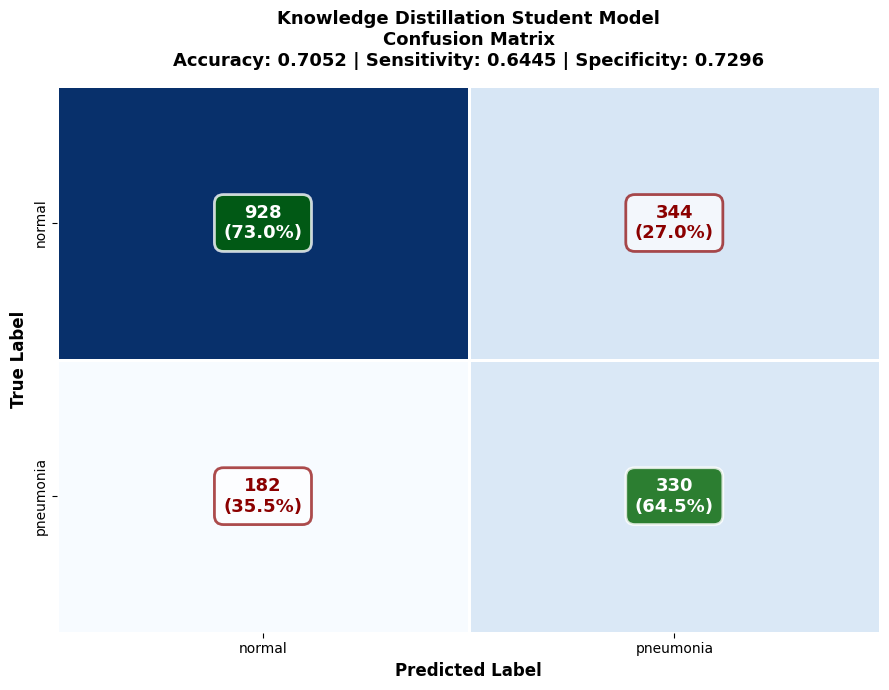

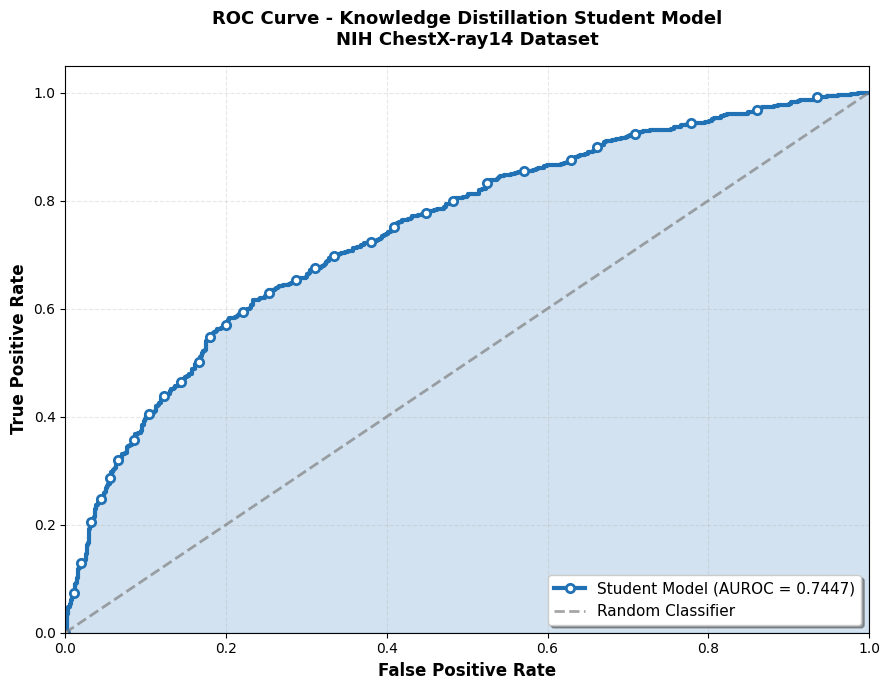

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, confusion_matrix

# Confusion Matrix with improved color scheme
plt.figure(figsize=(9, 7))
cm = confusion_matrix(all_labels, predicted_classes)

# Create custom colormap - darker blues for diagonal
colors = ['#f7fbff', '#deebf7', '#c6dbef', '#6baed6', '#2171b5', '#08519c', '#08306b']
custom_cmap = sns.blend_palette(colors, as_cmap=True)

ax = sns.heatmap(cm, annot=False, fmt='d', cmap=custom_cmap,
                 xticklabels=class_names, yticklabels=class_names,
                 cbar=False, linewidths=2, linecolor='white')

# Add annotations with contrasting colors
for i in range(2):
    for j in range(2):
        value = cm[i, j]
        total = cm[i, :].sum()
        pct = value / total * 100 if total > 0 else 0

        # Diagonal gets white text on dark background
        # Off-diagonal gets dark text on light background
        if i == j:
            color = 'white'
            bbox_props = dict(boxstyle='round,pad=0.5', facecolor='darkgreen',
                            edgecolor='white', linewidth=2, alpha=0.8)
        else:
            color = 'darkred'
            bbox_props = dict(boxstyle='round,pad=0.5', facecolor='white',
                            edgecolor='darkred', linewidth=2, alpha=0.7)

        ax.text(j + 0.5, i + 0.5, f"{value}\n({pct:.1f}%)",
               ha='center', va='center', color=color,
               fontsize=13, fontweight='bold', bbox=bbox_props)

tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

plt.title(f"Knowledge Distillation Student Model\nConfusion Matrix\n" +
          f"Accuracy: {accuracy:.4f} | Sensitivity: {sensitivity:.4f} | Specificity: {specificity:.4f}",
         fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Predicted Label", fontsize=12, fontweight='bold')
plt.ylabel("True Label", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# ROC Curve with enhanced styling
fpr, tpr, _ = roc_curve(all_labels, all_predictions)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(9, 7))
plt.plot(fpr, tpr, color='#2171b5', linewidth=3,
         label=f'Student Model (AUROC = {roc_auc:.4f})', marker='o',
         markevery=20, markersize=6, markerfacecolor='white', markeredgewidth=2)
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=2,
         label='Random Classifier', alpha=0.7)
plt.fill_between(fpr, tpr, alpha=0.2, color='#2171b5')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
plt.title('ROC Curve - Knowledge Distillation Student Model\nNIH ChestX-ray14 Dataset',
         fontsize=13, fontweight='bold', pad=15)
plt.legend(loc="lower right", fontsize=11, frameon=True, shadow=True)
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

#### **NIH EfficientNetB4 Alternative**

In [ ]:
import tensorflow as tf
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (classification_report, confusion_matrix,
                            roc_auc_score, accuracy_score, roc_curve, auc,
                            precision_score, f1_score)

print("TensorFlow version:", tf.__version__)

# from google.colab import drive
# drive.mount('/content/drive')

import gc
tf.keras.backend.clear_session()
gc.collect()

TensorFlow version: 2.19.0


0

In [ ]:
NIH_TRAIN_DIR = "/content/drive/MyDrive/NIH_processed/train"
NIH_TEST_DIR = "/content/drive/MyDrive/NIH_processed/test"
TEACHER_MODEL_PATH = "/content/drive/MyDrive/NIH_models/Results/EffNetB4_epoch_15.h5"
OUTPUT_DIR = "/content/drive/MyDrive/NIH_models/KD_EfficientNetB4_v2"
os.makedirs(OUTPUT_DIR, exist_ok=True)

BATCH_SIZE = 16
IMG_SIZE = (224, 224)
EPOCHS = 15
TEMPERATURE = 4
ALPHA = 0.5
SEED = 123

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Configuration complete")

Configuration complete


In [ ]:
print("Preparing NIH dataset...")

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    NIH_TRAIN_DIR,
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset='training',
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    NIH_TRAIN_DIR,
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset='validation',
    shuffle=True,
    seed=SEED
)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    NIH_TEST_DIR,
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = test_ds.class_names
print(f"Classes: {class_names}")

Preparing NIH dataset...
Found 5320 files belonging to 2 classes.
Using 4256 files for training.
Found 5320 files belonging to 2 classes.
Using 1064 files for validation.
Found 1784 files belonging to 2 classes.
Classes: ['normal', 'pneumonia']


In [ ]:
def count_classes(directory):
    counts = {}
    for class_name in os.listdir(directory):
        class_path = os.path.join(directory, class_name)
        if os.path.isdir(class_path):
            counts[class_name] = len([f for f in os.listdir(class_path)
                                     if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
    return counts

train_counts = count_classes(NIH_TRAIN_DIR)
total = sum(train_counts.values())
class_weights = {i: total / (len(train_counts) * count)
                for i, count in enumerate(train_counts.values())}

print(f"Class weights: {class_weights}")

Class weights: {0: 2.1262989608313347, 1: 0.6537232735315802}


In [ ]:
print("Loading teacher model (EfficientNetB4)...")

from tensorflow.keras.applications import EfficientNetB4
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Rescaling, Input
from tensorflow.keras.models import Model

inputs = Input(shape=(224, 224, 3))
x = Rescaling(1.0 / 255)(inputs)
x = tf.keras.applications.efficientnet.preprocess_input(x * 255.0)

base_model = EfficientNetB4(include_top=False, weights='imagenet', input_tensor=x)
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(1, activation='sigmoid')(x)

teacher_model = Model(inputs=inputs, outputs=outputs)
teacher_model.load_weights(TEACHER_MODEL_PATH)
teacher_model.trainable = False

print("Teacher model loaded successfully")

Loading teacher model (EfficientNetB4)...
71686520/71686520 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Teacher model loaded successfully


In [ ]:
print("Creating student model (MobileNetV2)...")

from tensorflow.keras.applications import MobileNetV2

student_inputs = Input(shape=(224, 224, 3))
student_x = Rescaling(1.0 / 255)(student_inputs)
student_x = tf.keras.applications.mobilenet_v2.preprocess_input(student_x * 255.0)

student_base = MobileNetV2(include_top=False, weights='imagenet', input_tensor=student_x)
student_x = student_base.output
student_x = GlobalAveragePooling2D()(student_x)
student_x = Dense(128, activation='relu')(student_x)
student_x = Dropout(0.3)(student_x)
student_outputs = Dense(1, activation='sigmoid')(student_x)

student_model = Model(inputs=student_inputs, outputs=student_outputs)

print("Student model created")

Creating student model (MobileNetV2)...


/tmp/ipython-input-2961199243.py:9: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  student_base = MobileNetV2(include_top=False, weights='imagenet', input_tensor=student_x)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Student model created


In [ ]:
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fn(y_true, y_pred):
        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1.0 - epsilon)

        bce = -y_true * tf.math.log(y_pred)
        focal_weight = alpha * tf.pow(1 - y_pred, gamma)
        loss = focal_weight * bce

        return tf.reduce_mean(loss)
    return focal_loss_fn

class DistillationLoss:
    def __init__(self, temperature=4, alpha=0.5):
        self.temperature = temperature
        self.alpha = alpha
        self.focal_loss_fn = focal_loss(gamma=2.0, alpha=0.25)
        self.bce = tf.keras.losses.BinaryCrossentropy()

    def __call__(self, y_true, student_pred, teacher_pred):
        student_loss = self.focal_loss_fn(y_true, student_pred)

        teacher_soft = tf.nn.sigmoid(teacher_pred / self.temperature)
        student_soft = tf.nn.sigmoid(student_pred / self.temperature)

        distillation_loss = self.bce(teacher_soft, student_soft)

        total_loss = self.alpha * distillation_loss + (1 - self.alpha) * student_loss
        return total_loss

print("Distillation loss defined")

Distillation loss defined


In [ ]:
print("Starting distillation training...")

import gc
gc.collect()

optimizer = tf.keras.optimizers.Adam(learning_rate=5e-5)
distill_loss_fn = DistillationLoss(temperature=TEMPERATURE, alpha=ALPHA)

train_loss_metric = tf.keras.metrics.Mean()
train_acc_metric = tf.keras.metrics.BinaryAccuracy()
val_loss_metric = tf.keras.metrics.Mean()
val_acc_metric = tf.keras.metrics.BinaryAccuracy()

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_loss_metric.reset_state()
    train_acc_metric.reset_state()

    for images, labels in train_ds:
        sample_weights = tf.where(labels == 0,
                                  class_weights[0],
                                  class_weights[1])

        teacher_predictions = teacher_model(images, training=False)

        with tf.GradientTape() as tape:
            student_predictions = student_model(images, training=True)
            loss = distill_loss_fn(labels, student_predictions, teacher_predictions)
            weighted_loss = loss * tf.reduce_mean(sample_weights)

        gradients = tape.gradient(weighted_loss, student_model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, student_model.trainable_variables))

        train_loss_metric.update_state(weighted_loss)
        train_acc_metric.update_state(labels, student_predictions)

    val_loss_metric.reset_state()
    val_acc_metric.reset_state()

    for images, labels in val_ds:
        teacher_predictions = teacher_model(images, training=False)
        student_predictions = student_model(images, training=False)

        val_loss = distill_loss_fn(labels, student_predictions, teacher_predictions)
        val_loss_metric.update_state(val_loss)
        val_acc_metric.update_state(labels, student_predictions)

    train_loss = train_loss_metric.result().numpy()
    train_acc = train_acc_metric.result().numpy()
    val_loss = val_loss_metric.result().numpy()
    val_acc = val_acc_metric.result().numpy()

    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

    epoch_path = os.path.join(OUTPUT_DIR, f"student_epoch_{epoch+1:02d}.keras")
    student_model.save(epoch_path)
    print(f"Saved: student_epoch_{epoch+1:02d}.keras")

print("\nTraining completed")

Starting distillation training...

Epoch 1/15
Train Loss: 0.6203, Train Acc: 0.2568
Val Loss: 0.3495, Val Acc: 0.4981
Saved: student_epoch_01.keras

Epoch 2/15
Train Loss: 0.6195, Train Acc: 0.2951
Val Loss: 0.3508, Val Acc: 0.6551
Saved: student_epoch_02.keras

Epoch 3/15
Train Loss: 0.6191, Train Acc: 0.3896
Val Loss: 0.3492, Val Acc: 0.6062
Saved: student_epoch_03.keras

Epoch 4/15
Train Loss: 0.6188, Train Acc: 0.4899
Val Loss: 0.3497, Val Acc: 0.6476
Saved: student_epoch_04.keras

Epoch 5/15
Train Loss: 0.6185, Train Acc: 0.5590
Val Loss: 0.3518, Val Acc: 0.6992
Saved: student_epoch_05.keras

Epoch 6/15
Train Loss: 0.6184, Train Acc: 0.5975
Val Loss: 0.3519, Val Acc: 0.6598
Saved: student_epoch_06.keras

Epoch 7/15
Train Loss: 0.6181, Train Acc: 0.6426
Val Loss: 0.3554, Val Acc: 0.7105
Saved: student_epoch_07.keras

Epoch 8/15
Train Loss: 0.6182, Train Acc: 0.6288
Val Loss: 0.3589, Val Acc: 0.7519
Saved: student_epoch_08.keras

Epoch 9/15
Train Loss: 0.6179, Train Acc: 0.7042
Val 

In [ ]:
print("\n" + "="*70)
print("EVALUATING ALL EPOCHS TO FIND BEST MODEL")
print("="*70)

epoch_results = []

for epoch in range(1, EPOCHS + 1):
    epoch_path = os.path.join(OUTPUT_DIR, f"student_epoch_{epoch:02d}.keras")

    if not os.path.exists(epoch_path):
        continue

    epoch_model = tf.keras.models.load_model(epoch_path)

    all_predictions = []
    all_labels = []

    for images, labels in test_ds:
        predictions = epoch_model.predict(images, verbose=0)
        all_predictions.extend(predictions.flatten())
        all_labels.extend(labels.numpy())

    all_predictions = np.array(all_predictions)
    all_labels = np.array(all_labels)
    predicted_classes = (all_predictions > 0.5).astype(int)

    accuracy = accuracy_score(all_labels, predicted_classes)
    auroc = roc_auc_score(all_labels, all_predictions)

    cm = confusion_matrix(all_labels, predicted_classes)
    tn, fp, fn, tp = cm.ravel()
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    balanced_acc = (sensitivity + specificity) / 2
    composite_score = 0.4 * auroc + 0.3 * accuracy + 0.3 * balanced_acc

    epoch_results.append({
        'epoch': epoch,
        'accuracy': accuracy,
        'auroc': auroc,
        'sensitivity': sensitivity,
        'specificity': specificity,
        'balanced_acc': balanced_acc,
        'composite_score': composite_score
    })

    print(f"\nEpoch {epoch:02d}: Acc={accuracy:.4f}, AUROC={auroc:.4f}, Sens={sensitivity:.4f}, Spec={specificity:.4f}, Balanced={balanced_acc:.4f}, Composite={composite_score:.4f}")

best_epoch = max(epoch_results, key=lambda x: x['composite_score'])

print("\n" + "="*70)
print("BEST EPOCH BASED ON COMPOSITE SCORE")
print("="*70)
print(f"\nBest Epoch: {best_epoch['epoch']}")
print(f"Accuracy:      {best_epoch['accuracy']:.4f}")
print(f"AUROC:         {best_epoch['auroc']:.4f}")
print(f"Sensitivity:   {best_epoch['sensitivity']:.4f}")
print(f"Specificity:   {best_epoch['specificity']:.4f}")
print(f"Balanced Acc:  {best_epoch['balanced_acc']:.4f}")
print(f"Composite:     {best_epoch['composite_score']:.4f}")

best_model_path = os.path.join(OUTPUT_DIR, f"student_epoch_{best_epoch['epoch']:02d}.keras")
student_model = tf.keras.models.load_model(best_model_path)

student_model.save(os.path.join(OUTPUT_DIR, "student_model_final.keras"))
print(f"\nBest model saved as: student_model_final.keras")


EVALUATING ALL EPOCHS TO FIND BEST MODEL

Epoch 01: Acc=0.5135, AUROC=0.6554, Sens=0.7715, Spec=0.4096, Balanced=0.5905, Composite=0.5934

Epoch 02: Acc=0.6525, AUROC=0.6989, Sens=0.6621, Spec=0.6486, Balanced=0.6553, Composite=0.6719

Epoch 03: Acc=0.6087, AUROC=0.7233, Sens=0.7930, Spec=0.5346, Balanced=0.6638, Composite=0.6711

Epoch 04: Acc=0.6626, AUROC=0.7355, Sens=0.7520, Spec=0.6266, Balanced=0.6893, Composite=0.6997

Epoch 05: Acc=0.6956, AUROC=0.7426, Sens=0.6836, Spec=0.7005, Balanced=0.6920, Composite=0.7133

Epoch 06: Acc=0.6626, AUROC=0.7444, Sens=0.7539, Spec=0.6258, Balanced=0.6898, Composite=0.7035

Epoch 07: Acc=0.7052, AUROC=0.7394, Sens=0.5977, Spec=0.7484, Balanced=0.6730, Composite=0.7092

Epoch 08: Acc=0.7298, AUROC=0.7342, Sens=0.4395, Spec=0.8467, Balanced=0.6431, Composite=0.7055

Epoch 09: Acc=0.7326, AUROC=0.7368, Sens=0.1191, Spec=0.9796, Balanced=0.5494, Composite=0.6793

Epoch 10: Acc=0.7416, AUROC=0.7303, Sens=0.4043, Spec=0.8774, Balanced=0.6408, Compo

In [ ]:
print("\n" + "="*70)
print("EVALUATING ALL EPOCHS TO FIND BEST MODEL")
print("="*70)

epoch_results = []

for epoch in range(1, EPOCHS + 1):
    epoch_path = os.path.join(OUTPUT_DIR, f"student_epoch_{epoch:02d}.keras")

    if not os.path.exists(epoch_path):
        continue

    epoch_model = tf.keras.models.load_model(epoch_path)

    all_predictions = []
    all_labels = []

    for images, labels in test_ds:
        predictions = epoch_model.predict(images, verbose=0)
        all_predictions.extend(predictions.flatten())
        all_labels.extend(labels.numpy())

    all_predictions = np.array(all_predictions)
    all_labels = np.array(all_labels)
    predicted_classes = (all_predictions > 0.5).astype(int)

    accuracy = accuracy_score(all_labels, predicted_classes)
    auroc = roc_auc_score(all_labels, all_predictions)

    cm = confusion_matrix(all_labels, predicted_classes)
    tn, fp, fn, tp = cm.ravel()
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    balanced_acc = (sensitivity + specificity) / 2
    composite_score = 0.4 * auroc + 0.3 * accuracy + 0.3 * balanced_acc

    epoch_results.append({
        'epoch': epoch,
        'accuracy': accuracy,
        'auroc': auroc,
        'sensitivity': sensitivity,
        'specificity': specificity,
        'balanced_acc': balanced_acc,
        'composite_score': composite_score
    })

    print(f"\nEpoch {epoch:02d}: Acc={accuracy:.4f}, AUROC={auroc:.4f}, Sens={sensitivity:.4f}, Spec={specificity:.4f}, Balanced={balanced_acc:.4f}, Composite={composite_score:.4f}")

best_epoch = max(epoch_results, key=lambda x: x['composite_score'])

print("\n" + "="*70)
print("BEST EPOCH BASED ON COMPOSITE SCORE")
print("="*70)
print(f"\nBest Epoch: {best_epoch['epoch']}")
print(f"Accuracy:      {best_epoch['accuracy']:.4f}")
print(f"AUROC:         {best_epoch['auroc']:.4f}")
print(f"Sensitivity:   {best_epoch['sensitivity']:.4f}")
print(f"Specificity:   {best_epoch['specificity']:.4f}")
print(f"Balanced Acc:  {best_epoch['balanced_acc']:.4f}")
print(f"Composite:     {best_epoch['composite_score']:.4f}")

best_model_path = os.path.join(OUTPUT_DIR, f"student_epoch_{best_epoch['epoch']:02d}.keras")
student_model = tf.keras.models.load_model(best_model_path)

student_model.save(os.path.join(OUTPUT_DIR, "student_model_final.keras"))
print(f"\nBest model saved as: student_model_final.keras")


EVALUATING ALL EPOCHS TO FIND BEST MODEL

Epoch 01: Acc=0.5135, AUROC=0.6554, Sens=0.7715, Spec=0.4096, Balanced=0.5905, Composite=0.5934

Epoch 02: Acc=0.6525, AUROC=0.6989, Sens=0.6621, Spec=0.6486, Balanced=0.6553, Composite=0.6719

Epoch 03: Acc=0.6087, AUROC=0.7233, Sens=0.7930, Spec=0.5346, Balanced=0.6638, Composite=0.6711

Epoch 04: Acc=0.6626, AUROC=0.7355, Sens=0.7520, Spec=0.6266, Balanced=0.6893, Composite=0.6997

Epoch 05: Acc=0.6956, AUROC=0.7426, Sens=0.6836, Spec=0.7005, Balanced=0.6920, Composite=0.7133

Epoch 06: Acc=0.6626, AUROC=0.7444, Sens=0.7539, Spec=0.6258, Balanced=0.6898, Composite=0.7035

Epoch 07: Acc=0.7052, AUROC=0.7394, Sens=0.5977, Spec=0.7484, Balanced=0.6730, Composite=0.7092

Epoch 08: Acc=0.7298, AUROC=0.7342, Sens=0.4395, Spec=0.8467, Balanced=0.6431, Composite=0.7055

Epoch 09: Acc=0.7326, AUROC=0.7368, Sens=0.1191, Spec=0.9796, Balanced=0.5494, Composite=0.6793

Epoch 10: Acc=0.7416, AUROC=0.7303, Sens=0.4043, Spec=0.8774, Balanced=0.6408, Compo

## **EfficientNetB4 Student Model Hypertuning**

In [ ]:
import tensorflow as tf
import numpy as np
import os
from sklearn.metrics import (classification_report, confusion_matrix,
                            roc_auc_score, accuracy_score,
                            precision_score, recall_score, f1_score)
import matplotlib.pyplot as plt
import seaborn as sns

print("TensorFlow version:", tf.__version__)

# from google.colab import drive
# drive.mount('/content/drive')

TensorFlow version: 2.19.0


In [ ]:
NIH_TRAIN_DIR = "/content/drive/MyDrive/NIH_processed/train"
NIH_TEST_DIR = "/content/drive/MyDrive/NIH_processed/test"
TEACHER_MODEL_PATH = "/content/drive/MyDrive/NIH_models/Results/EffNetB4_epoch_15.h5"
OUTPUT_DIR_GRID = "/content/drive/MyDrive/NIH_models/Knowledge_Distillation_GridSearch"
os.makedirs(OUTPUT_DIR_GRID, exist_ok=True)

BATCH_SIZE = 32
IMG_SIZE = (224, 224)
EPOCHS = 15
SEED = 123

grid_configs = [
    {'temp': 3, 'alpha': 0.5, 'lr': 5e-5, 'name': 'T3_A05'},
    {'temp': 4, 'alpha': 0.4, 'lr': 5e-5, 'name': 'T4_A04'},
    {'temp': 4, 'alpha': 0.6, 'lr': 5e-5, 'name': 'T4_A06'},
    {'temp': 5, 'alpha': 0.5, 'lr': 5e-5, 'name': 'T5_A05'},
]

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Grid search configuration set")
print(f"Testing {len(grid_configs)} configurations")
for config in grid_configs:
    print(f"  {config['name']}: T={config['temp']}, Alpha={config['alpha']}, LR={config['lr']}")

Grid search configuration set
Testing 4 configurations
  T3_A05: T=3, Alpha=0.5, LR=5e-05
  T4_A04: T=4, Alpha=0.4, LR=5e-05
  T4_A06: T=4, Alpha=0.6, LR=5e-05
  T5_A05: T=5, Alpha=0.5, LR=5e-05


In [ ]:
print("Preparing datasets...")

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    NIH_TRAIN_DIR,
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset='training',
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    NIH_TRAIN_DIR,
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset='validation',
    shuffle=True,
    seed=SEED
)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    NIH_TEST_DIR,
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = test_ds.class_names
print(f"Class names: {class_names}")
print("Data preparation complete")

Preparing datasets...
Found 5320 files belonging to 2 classes.
Using 4256 files for training.
Found 5320 files belonging to 2 classes.
Using 1064 files for validation.
Found 1784 files belonging to 2 classes.
Class names: ['normal', 'pneumonia']
Data preparation complete


In [ ]:
def count_classes(directory):
    counts = {}
    for class_name in os.listdir(directory):
        class_path = os.path.join(directory, class_name)
        if os.path.isdir(class_path):
            counts[class_name] = len([f for f in os.listdir(class_path)
                                     if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
    return counts

train_counts = count_classes(NIH_TRAIN_DIR)
total = sum(train_counts.values())
class_weights = {i: total / (len(train_counts) * count)
                for i, count in enumerate(train_counts.values())}

print(f"Train counts: {train_counts}")
print(f"Class weights: {class_weights}")

Train counts: {'pneumonia': 1251, 'normal': 4069}
Class weights: {0: 2.1262989608313347, 1: 0.6537232735315802}


In [ ]:
print("Loading teacher model (EfficientNetB4)...")

from tensorflow.keras.applications import EfficientNetB4
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Rescaling, Input
from tensorflow.keras.models import Model

teacher_inputs = Input(shape=(224, 224, 3))
teacher_x = Rescaling(1.0 / 255)(teacher_inputs)
teacher_x = tf.keras.applications.efficientnet.preprocess_input(teacher_x * 255.0)

teacher_base = EfficientNetB4(include_top=False, weights='imagenet', input_tensor=teacher_x)
teacher_x = teacher_base.output
teacher_x = GlobalAveragePooling2D()(teacher_x)
teacher_x = Dense(256, activation='relu')(teacher_x)
teacher_x = Dropout(0.5)(teacher_x)
teacher_outputs = Dense(1, activation='sigmoid')(teacher_x)

teacher_model = Model(inputs=teacher_inputs, outputs=teacher_outputs)
teacher_model.load_weights(TEACHER_MODEL_PATH)
teacher_model.trainable = False

print("Teacher model loaded successfully")

Loading teacher model (EfficientNetB4)...
71686520/71686520 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Teacher model loaded successfully


In [ ]:
# print("Creating student model (MobileNetV2)...")

# from tensorflow.keras.applications import MobileNetV2

# tf.keras.backend.clear_session()

# student_inputs = Input(shape=(224, 224, 3))
# student_x = Rescaling(1.0 / 255)(student_inputs)
# student_x = tf.keras.applications.mobilenet_v2.preprocess_input(student_x * 255.0)

# student_base = MobileNetV2(include_top=False, weights='imagenet', input_tensor=student_x)
# student_x = student_base.output
# student_x = GlobalAveragePooling2D()(student_x)
# student_x = Dense(128, activation='relu')(student_x)
# student_x = Dropout(0.3)(student_x)
# student_outputs = Dense(1, activation='sigmoid')(student_x)

# student_model_tuned = Model(inputs=student_inputs, outputs=student_outputs)

# print("Student model created successfully")

Creating student model (MobileNetV2)...


/tmp/ipython-input-1105381071.py:11: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  student_base = MobileNetV2(include_top=False, weights='imagenet', input_tensor=student_x)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Student model created successfully


In [ ]:
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1.0 - epsilon)

        bce = -y_true * tf.math.log(y_pred)
        focal_weight = alpha * tf.pow(1 - y_pred, gamma)
        loss = focal_weight * bce

        return tf.reduce_mean(loss)
    return focal_loss_fixed

class DistillationLoss:
    def __init__(self, temperature=4, alpha=0.5):
        self.temperature = temperature
        self.alpha = alpha
        self.focal_loss_fn = focal_loss(gamma=2.0, alpha=0.25)
        self.bce = tf.keras.losses.BinaryCrossentropy()

    def __call__(self, y_true, student_pred, teacher_pred):
        student_loss = self.focal_loss_fn(y_true, student_pred)

        teacher_soft = tf.nn.sigmoid(teacher_pred / self.temperature)
        student_soft = tf.nn.sigmoid(student_pred / self.temperature)

        distillation_loss = self.bce(teacher_soft, student_soft)

        total_loss = self.alpha * distillation_loss + (1 - self.alpha) * student_loss
        return total_loss

print("Distillation loss defined (original version)")

Distillation loss defined (original version)


In [ ]:
print("Starting grid search...")

import gc
from tensorflow.keras.applications import MobileNetV2


grid_results = []

for config_idx, config in enumerate(grid_configs):
    print(f"\n{'='*70}")
    print(f"GRID SEARCH {config_idx + 1}/{len(grid_configs)}: {config['name']}")
    print(f"Temperature={config['temp']}, Alpha={config['alpha']}, LR={config['lr']}")
    print(f"{'='*70}")

    tf.keras.backend.clear_session()
    gc.collect()

    student_inputs = Input(shape=(224, 224, 3))
    student_x = Rescaling(1.0 / 255)(student_inputs)
    student_x = tf.keras.applications.mobilenet_v2.preprocess_input(student_x * 255.0)

    student_base = MobileNetV2(include_top=False, weights='imagenet', input_tensor=student_x)
    student_x = student_base.output
    student_x = GlobalAveragePooling2D()(student_x)
    student_x = Dense(128, activation='relu')(student_x)
    student_x = Dropout(0.3)(student_x)
    student_outputs = Dense(1, activation='sigmoid')(student_x)

    student_model_grid = Model(inputs=student_inputs, outputs=student_outputs)

    optimizer_grid = tf.keras.optimizers.Adam(learning_rate=config['lr'])
    distill_loss_fn_grid = DistillationLoss(temperature=config['temp'], alpha=config['alpha'])

    config_dir = os.path.join(OUTPUT_DIR_GRID, config['name'])
    os.makedirs(config_dir, exist_ok=True)

    train_loss_metric = tf.keras.metrics.Mean()
    train_acc_metric = tf.keras.metrics.BinaryAccuracy()
    val_loss_metric = tf.keras.metrics.Mean()
    val_acc_metric = tf.keras.metrics.BinaryAccuracy()

    best_val_acc = 0.0
    patience_counter = 0

    for epoch in range(EPOCHS):
        print(f"\nEpoch {epoch + 1}/{EPOCHS}")

        train_loss_metric.reset_state()
        train_acc_metric.reset_state()

        for images, labels in train_ds:
            sample_weights = tf.where(labels == 0, class_weights[0], class_weights[1])
            teacher_predictions = teacher_model(images, training=False)

            with tf.GradientTape() as tape:
                student_predictions = student_model_grid(images, training=True)
                loss = distill_loss_fn_grid(labels, student_predictions, teacher_predictions)
                weighted_loss = loss * tf.reduce_mean(sample_weights)

            gradients = tape.gradient(weighted_loss, student_model_grid.trainable_variables)
            optimizer_grid.apply_gradients(zip(gradients, student_model_grid.trainable_variables))

            train_loss_metric.update_state(weighted_loss)
            train_acc_metric.update_state(labels, student_predictions)

        val_loss_metric.reset_state()
        val_acc_metric.reset_state()

        for images, labels in val_ds:
            teacher_predictions = teacher_model(images, training=False)
            student_predictions = student_model_grid(images, training=False)

            val_loss = distill_loss_fn_grid(labels, student_predictions, teacher_predictions)
            val_loss_metric.update_state(val_loss)
            val_acc_metric.update_state(labels, student_predictions)

        train_loss = train_loss_metric.result().numpy()
        train_acc = train_acc_metric.result().numpy()
        val_loss = val_loss_metric.result().numpy()
        val_acc = val_acc_metric.result().numpy()

        print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
        print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

        student_model_grid.save(os.path.join(config_dir, f"student_epoch_{epoch+1:02d}.keras"))

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            patience_counter = 0
            print(f"Saved epoch {epoch+1}")
        else:
            patience_counter += 1
            if patience_counter >= 5:
                print("Early stopping")
                break

    grid_results.append({
        'config': config,
        'config_dir': config_dir
    })

print("\n" + "="*70)
print("GRID SEARCH TRAINING COMPLETED")
print("="*70)

Starting grid search...

GRID SEARCH 1/4: T3_A05
Temperature=3, Alpha=0.5, LR=5e-05


/tmp/ipython-input-1782888128.py:22: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  student_base = MobileNetV2(include_top=False, weights='imagenet', input_tensor=student_x)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Epoch 1/15
Train Loss: 0.6214, Train Acc: 0.2899
Val Loss: 0.3487, Val Acc: 0.4192
Saved epoch 1

Epoch 2/15
Train Loss: 0.6199, Train Acc: 0.3844
Val Loss: 0.3557, Val Acc: 0.7462
Saved epoch 2

Epoch 3/15
Train Loss: 0.6190, Train Acc: 0.5230
Val Loss: 0.3537, Val Acc: 0.7312

Epoch 4/15
Train Loss: 0.6182, Train Acc: 0.6273
Val Loss: 0.3491, Val Acc: 0.6391

Epoch 5/15
Train Loss: 0.6176, Train Acc: 0.7002
Val Loss: 0.3575, Val Acc: 0.7594
Saved epoch 5

Epoch 6/15
Train Loss: 0.6172, Train Acc: 0.7535
Val Loss: 0.3596, Val Acc: 0.7491

Epoch 7/15
Train Loss: 0.6170, Train Acc: 0.7864
Val Loss: 0.3535, Val Acc: 0.7143

Epoch 8/15
Train Loss: 0.6168, Train Acc: 0.8071
Val Loss: 0.3637, Val Acc: 0.7707
Saved epoch 8

Epoch 9/15
Train Loss: 0.6169, Train Acc: 0.7928
Val Loss: 0.3552, Val Acc: 0.7039

Epoch 10/15
Train Loss: 0.6164, Train Acc: 0.8409
Val Loss: 0.3512, Val Acc: 0.6250

Epoch 11/15
Train Loss: 0.6163, Train Acc: 0.8562
Val

In [ ]:
# Reconstruct grid results from saved files
print("Reconstructing grid search results from saved models...")

OUTPUT_DIR_GRID = "/content/drive/MyDrive/NIH_models/Knowledge_Distillation_GridSearch"

grid_configs = [
    {'temp': 3, 'alpha': 0.5, 'lr': 5e-5, 'name': 'T3_A05'},
    {'temp': 4, 'alpha': 0.4, 'lr': 5e-5, 'name': 'T4_A04'},
    {'temp': 4, 'alpha': 0.6, 'lr': 5e-5, 'name': 'T4_A06'},
    {'temp': 5, 'alpha': 0.5, 'lr': 5e-5, 'name': 'T5_A05'},
]

grid_results = []

for config in grid_configs:
    config_dir = os.path.join(OUTPUT_DIR_GRID, config['name'])

    if os.path.exists(config_dir):
        saved_epochs = [f for f in os.listdir(config_dir) if f.startswith('student_epoch_')]

        if saved_epochs:
            grid_results.append({
                'config': config,
                'config_dir': config_dir
            })
            print(f"Found {config['name']}: {len(saved_epochs)} epochs saved")
        else:
            print(f"Warning: {config['name']} directory exists but no epochs found")
    else:
        print(f"Warning: {config['name']} directory not found")

print(f"\nRecovered {len(grid_results)} configurations")
print("Ready to evaluate!")

Reconstructing grid search results from saved models...
Found T3_A05: 13 epochs saved
Found T4_A04: 14 epochs saved
Found T4_A06: 15 epochs saved
Found T5_A05: 8 epochs saved

Recovered 4 configurations
Ready to evaluate!


In [ ]:
print("\n" + "="*70)
print("EVALUATING ALL GRID SEARCH CONFIGURATIONS")
print("="*70)

all_config_results = []

for result in grid_results:
    config = result['config']
    config_dir = result['config_dir']

    print(f"\n{'='*70}")
    print(f"Evaluating: {config['name']}")
    print(f"{'='*70}")

    epoch_results = []

    for epoch in range(1, EPOCHS + 1):
        epoch_path = os.path.join(config_dir, f"student_epoch_{epoch:02d}.keras")

        if not os.path.exists(epoch_path):
            continue

        epoch_model = tf.keras.models.load_model(epoch_path)

        all_predictions = []
        all_labels = []

        for images, labels in test_ds:
            predictions = epoch_model.predict(images, verbose=0)
            all_predictions.extend(predictions.flatten())
            all_labels.extend(labels.numpy())

        all_predictions = np.array(all_predictions)
        all_labels = np.array(all_labels)
        predicted_classes = (all_predictions > 0.5).astype(int)

        accuracy = accuracy_score(all_labels, predicted_classes)
        auroc = roc_auc_score(all_labels, all_predictions)

        cm = confusion_matrix(all_labels, predicted_classes)
        tn, fp, fn, tp = cm.ravel()
        sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

        balanced_acc = (sensitivity + specificity) / 2
        sens_spec_diff = abs(sensitivity - specificity)
        balance_penalty = 1.0 - (sens_spec_diff * 0.5)

        composite_score = (0.3 * auroc +
                          0.3 * accuracy +
                          0.4 * balanced_acc * balance_penalty)

        epoch_results.append({
            'epoch': epoch,
            'accuracy': accuracy,
            'auroc': auroc,
            'sensitivity': sensitivity,
            'specificity': specificity,
            'balanced_acc': balanced_acc,
            'sens_spec_diff': sens_spec_diff,
            'composite_score': composite_score
        })

        print(f"Epoch {epoch:02d}: Acc={accuracy:.4f}, AUROC={auroc:.4f}, " +
              f"Sens={sensitivity:.4f}, Spec={specificity:.4f}, " +
              f"Diff={sens_spec_diff:.4f}, Score={composite_score:.4f}")

    if epoch_results:
        best_epoch = max(epoch_results, key=lambda x: x['composite_score'])
        best_epoch['config_name'] = config['name']
        best_epoch['config'] = config
        best_epoch['config_dir'] = config_dir

        all_config_results.append(best_epoch)

        print(f"\nBest for {config['name']}: Epoch {best_epoch['epoch']}, Score={best_epoch['composite_score']:.4f}")

overall_best = max(all_config_results, key=lambda x: x['composite_score'])

print("\n" + "="*70)
print("BEST GRID SEARCH MODEL")
print("="*70)
print(f"\nConfiguration: {overall_best['config_name']}")
print(f"Temperature: {overall_best['config']['temp']}")
print(f"Alpha: {overall_best['config']['alpha']}")
print(f"Epoch: {overall_best['epoch']}")
print(f"\nAccuracy:       {overall_best['accuracy']:.4f}")
print(f"AUROC:          {overall_best['auroc']:.4f}")
print(f"Sensitivity:    {overall_best['sensitivity']:.4f}")
print(f"Specificity:    {overall_best['specificity']:.4f}")
print(f"Balanced Acc:   {overall_best['balanced_acc']:.4f}")
print(f"Sens/Spec Diff: {overall_best['sens_spec_diff']:.4f}")

best_model_path = os.path.join(overall_best['config_dir'], f"student_epoch_{overall_best['epoch']:02d}.keras")
final_model = tf.keras.models.load_model(best_model_path)
final_model.save(os.path.join(OUTPUT_DIR_GRID, "student_model_best_grid.keras"))

print(f"\nBest model saved as: student_model_best_grid.keras")
print("="*70)


EVALUATING ALL GRID SEARCH CONFIGURATIONS

Evaluating: T3_A05
Epoch 01: Acc=0.4423, AUROC=0.6298, Sens=0.8535, Spec=0.2767, Diff=0.5768, Score=0.4825
Epoch 02: Acc=0.7136, AUROC=0.6837, Sens=0.3477, Spec=0.8608, Diff=0.5132, Score=0.5989
Epoch 03: Acc=0.7136, AUROC=0.7156, Sens=0.4824, Spec=0.8066, Diff=0.3242, Score=0.6448
Epoch 04: Acc=0.6508, AUROC=0.7322, Sens=0.7539, Spec=0.6093, Diff=0.1446, Score=0.6678
Epoch 05: Acc=0.7337, AUROC=0.7400, Sens=0.4980, Spec=0.8286, Diff=0.3306, Score=0.6636
Epoch 06: Acc=0.7343, AUROC=0.7458, Sens=0.5410, Spec=0.8121, Diff=0.2711, Score=0.6780
Epoch 07: Acc=0.7164, AUROC=0.7458, Sens=0.6367, Spec=0.7484, Diff=0.1117, Score=0.7002
Epoch 08: Acc=0.7304, AUROC=0.7434, Sens=0.4590, Spec=0.8396, Diff=0.3806, Score=0.6524
Epoch 09: Acc=0.7080, AUROC=0.7440, Sens=0.6484, Spec=0.7319, Diff=0.0835, Score=0.7001
Epoch 10: Acc=0.6525, AUROC=0.7410, Sens=0.7793, Spec=0.6014, Diff=0.1779, Score=0.6696
Epoch 11: Acc=0.5499, AUROC=0.7318, Sens=0.8691, Spec=0.4

In [ ]:
student_model = tf.keras.models.load_model(os.path.join(OUTPUT_DIR_GRID, "student_model_best_grid.keras"))

all_predictions = []
all_labels = []

for images, labels in test_ds:
    predictions = student_model.predict(images, verbose=0)
    all_predictions.extend(predictions.flatten())
    all_labels.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)
predicted_classes = (all_predictions > 0.5).astype(int)

accuracy = accuracy_score(all_labels, predicted_classes)
auroc = roc_auc_score(all_labels, all_predictions)

cm = confusion_matrix(all_labels, predicted_classes)
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

student_size_mb = os.path.getsize(os.path.join(OUTPUT_DIR_GRID, "student_model_best_grid.keras")) / (1024 * 1024)

print("\n" + "="*70)
print("FINAL EVALUATION - BEST GRID SEARCH MODEL")
print("="*70)
print(f"\nAccuracy:      {accuracy:.4f}")
print(f"AUROC:         {auroc:.4f}")
print(f"Sensitivity:   {sensitivity:.4f}")
print(f"Specificity:   {specificity:.4f}")
print(f"Model Size:    {student_size_mb:.2f} MB")

print("\nClassification Report:")
print(classification_report(all_labels, predicted_classes, target_names=class_names, digits=4))


FINAL EVALUATION - BEST GRID SEARCH MODEL

Accuracy:      0.7164
AUROC:         0.7458
Sensitivity:   0.6367
Specificity:   0.7484
Model Size:    9.79 MB

Classification Report:
              precision    recall  f1-score   support

      normal     0.8366    0.7484    0.7900      1272
   pneumonia     0.5046    0.6367    0.5630       512

    accuracy                         0.7164      1784
   macro avg     0.6706    0.6926    0.6765      1784
weighted avg     0.7413    0.7164    0.7249      1784



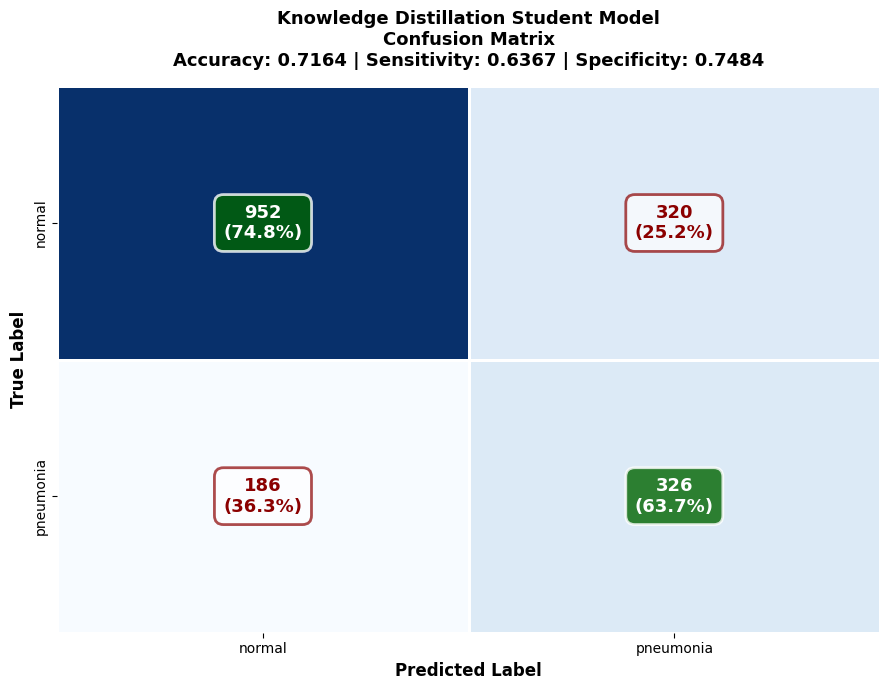

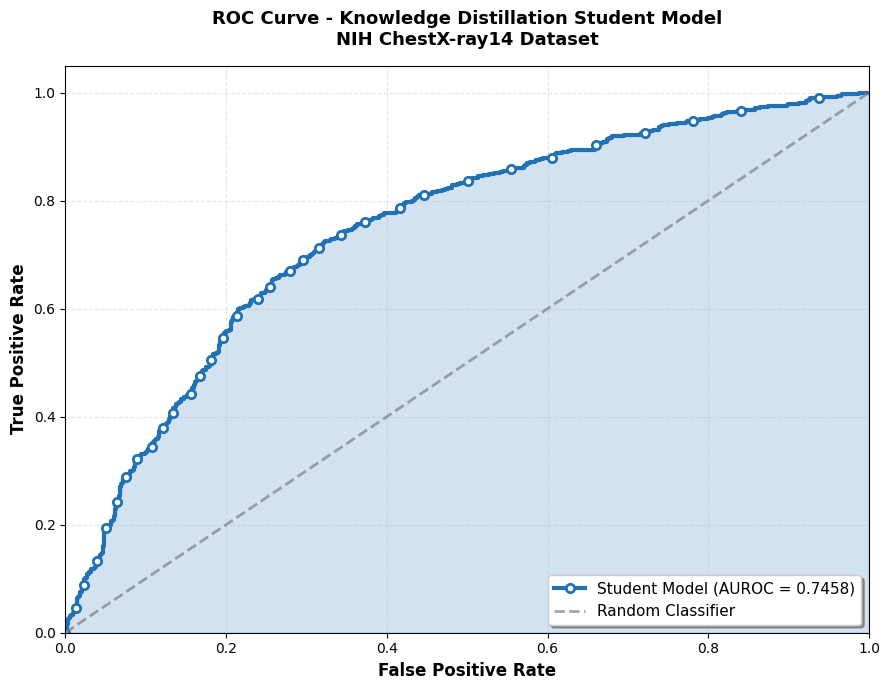

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(9, 7))
cm = confusion_matrix(all_labels, predicted_classes)

colors = ['#f7fbff', '#deebf7', '#c6dbef', '#6baed6', '#2171b5', '#08519c', '#08306b']
custom_cmap = sns.blend_palette(colors, as_cmap=True)

ax = sns.heatmap(cm, annot=False, fmt='d', cmap=custom_cmap,
                 xticklabels=class_names, yticklabels=class_names,
                 cbar=False, linewidths=2, linecolor='white')

for i in range(2):
    for j in range(2):
        value = cm[i, j]
        total = cm[i, :].sum()
        pct = value / total * 100 if total > 0 else 0

        if i == j:
            color = 'white'
            bbox_props = dict(boxstyle='round,pad=0.5', facecolor='darkgreen',
                            edgecolor='white', linewidth=2, alpha=0.8)
        else:
            color = 'darkred'
            bbox_props = dict(boxstyle='round,pad=0.5', facecolor='white',
                            edgecolor='darkred', linewidth=2, alpha=0.7)

        ax.text(j + 0.5, i + 0.5, f"{value}\n({pct:.1f}%)",
               ha='center', va='center', color=color,
               fontsize=13, fontweight='bold', bbox=bbox_props)

tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

plt.title(f"Knowledge Distillation Student Model\nConfusion Matrix\n" +
          f"Accuracy: {accuracy:.4f} | Sensitivity: {sensitivity:.4f} | Specificity: {specificity:.4f}",
         fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Predicted Label", fontsize=12, fontweight='bold')
plt.ylabel("True Label", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(all_labels, all_predictions)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(9, 7))
plt.plot(fpr, tpr, color='#2171b5', linewidth=3,
         label=f'Student Model (AUROC = {roc_auc:.4f})', marker='o',
         markevery=20, markersize=6, markerfacecolor='white', markeredgewidth=2)
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=2,
         label='Random Classifier', alpha=0.7)
plt.fill_between(fpr, tpr, alpha=0.2, color='#2171b5')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
plt.title('ROC Curve - Knowledge Distillation Student Model\nNIH ChestX-ray14 Dataset',
         fontsize=13, fontweight='bold', pad=15)
plt.legend(loc="lower right", fontsize=11, frameon=True, shadow=True)
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()



---



---



## **Mendeley**

In [ ]:
import tensorflow as tf
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (classification_report, confusion_matrix,
                            roc_auc_score, accuracy_score, roc_curve, auc,
                            precision_score, f1_score)

print("TensorFlow version:", tf.__version__)

# from google.colab import drive
# drive.mount('/content/drive')

import gc
tf.keras.backend.clear_session()
gc.collect()

TensorFlow version: 2.19.0


0

In [ ]:
MENDELEY_TRAIN_DIR = "/content/drive/MyDrive/chest_xray/train"
MENDELEY_TEST_DIR = "/content/drive/MyDrive/chest_xray/test"
TEACHER_PATH = "/content/drive/MyDrive/chest_xray/ensemble_models/Xception_weights-014-0.0046.keras"
OUTPUT_DIR = "/content/drive/MyDrive/chest_xray/Knowledge_Distillation_Xception_Final"
os.makedirs(OUTPUT_DIR, exist_ok=True)

BATCH_SIZE = 16
IMG_SIZE = (299, 299)
EPOCHS = 15
TEMPERATURE = 4
ALPHA = 0.5
SEED = 123

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Configuration complete")

Configuration complete


In [ ]:
print("Preparing Mendeley dataset...")

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    MENDELEY_TRAIN_DIR,
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset='training',
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    MENDELEY_TRAIN_DIR,
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset='validation',
    shuffle=True,
    seed=SEED
)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    MENDELEY_TEST_DIR,
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = test_ds.class_names
print(f"Classes: {class_names}")

Preparing Mendeley dataset...
Found 5232 files belonging to 2 classes.
Using 4186 files for training.
Found 5232 files belonging to 2 classes.
Using 1046 files for validation.
Found 624 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']


In [ ]:
def count_samples(directory):
    counts = {}
    for cls in os.listdir(directory):
        cls_path = os.path.join(directory, cls)
        if os.path.isdir(cls_path):
            counts[cls] = len([f for f in os.listdir(cls_path)
                             if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
    return counts

train_counts = count_samples(MENDELEY_TRAIN_DIR)
print(f"Training samples: {train_counts}")

total = sum(train_counts.values())
class_weights = {i: total / (len(train_counts) * count)
                for i, (_, count) in enumerate(sorted(train_counts.items()))}

print(f"Class weights: {class_weights}")
print(f"NORMAL weight: {class_weights[0]:.3f}, PNEUMONIA weight: {class_weights[1]:.3f}")

Training samples: {'NORMAL': 1349, 'PNEUMONIA': 3883}
Class weights: {0: 1.939214232765011, 1: 0.6737058975019315}
NORMAL weight: 1.939, PNEUMONIA weight: 0.674


In [ ]:
print("Loading teacher model (Xception)...")

def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fn(y_true, y_pred):
        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1.0 - epsilon)

        y_true = tf.cast(y_true, tf.float32)
        cross_entropy = -y_true * tf.math.log(y_pred)
        focal_weight = alpha * tf.pow(1 - y_pred, gamma)
        loss = focal_weight * cross_entropy

        return tf.reduce_mean(loss)
    return focal_loss_fn

teacher_model = tf.keras.models.load_model(
    TEACHER_PATH,
    custom_objects={'focal_loss_fn': focal_loss(gamma=2.0, alpha=0.25)}
)
teacher_model.trainable = False

print("Teacher model loaded successfully")
print(f"Teacher output shape: {teacher_model.output_shape}")

Loading teacher model (Xception)...
Teacher model loaded successfully
Teacher output shape: (None, 2)


In [ ]:
print("Creating student model (MobileNetV2)...")

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Input, Rescaling
from tensorflow.keras.models import Model

student_inputs = Input(shape=(299, 299, 3))
student_x = Rescaling(1.0 / 255)(student_inputs)
student_x = tf.keras.applications.mobilenet_v2.preprocess_input(student_x * 255.0)

student_base = MobileNetV2(include_top=False, weights='imagenet', input_tensor=student_x)
student_x = student_base.output
student_x = GlobalAveragePooling2D()(student_x)
student_x = Dense(128, activation='relu')(student_x)
student_x = Dropout(0.3)(student_x)
student_outputs = Dense(2, activation='softmax')(student_x)

student_model = Model(inputs=student_inputs, outputs=student_outputs)

print("Student model created")

Creating student model (MobileNetV2)...


/tmp/ipython-input-3886387949.py:11: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  student_base = MobileNetV2(include_top=False, weights='imagenet', input_tensor=student_x)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Student model created


In [ ]:
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fn(y_true, y_pred):
        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1.0 - epsilon)

        cross_entropy = -y_true * tf.math.log(y_pred)
        focal_weight = alpha * tf.pow(1 - y_pred, gamma)
        loss = focal_weight * cross_entropy

        return tf.reduce_mean(tf.reduce_sum(loss, axis=-1))
    return focal_loss_fn

class DistillationLoss:
    def __init__(self, temperature=4, alpha=0.5):
        self.temperature = temperature
        self.alpha = alpha
        self.focal_loss_fn = focal_loss(gamma=2.0, alpha=0.25)
        self.bce = tf.keras.losses.BinaryCrossentropy()

    def __call__(self, y_true, student_pred, teacher_pred):
        y_true_int = tf.cast(tf.squeeze(y_true), tf.int32)
        y_true_one_hot = tf.one_hot(y_true_int, depth=2)

        # Hard loss with focal loss
        student_loss = self.focal_loss_fn(y_true_one_hot, student_pred)

        # Soft loss from teacher
        teacher_soft = tf.nn.sigmoid(teacher_pred / self.temperature)
        student_soft = tf.nn.sigmoid(student_pred / self.temperature)

        distillation_loss = self.bce(teacher_soft, student_soft)

        # Combine
        total_loss = self.alpha * distillation_loss + (1 - self.alpha) * student_loss
        return total_loss

print("Distillation loss defined")

Distillation loss defined


In [ ]:
print("Starting distillation training...")

import gc
gc.collect()

optimizer = tf.keras.optimizers.Adam(learning_rate=5e-5)
distill_loss_fn = DistillationLoss(temperature=TEMPERATURE, alpha=ALPHA)

train_loss_metric = tf.keras.metrics.Mean()
train_acc_metric = tf.keras.metrics.BinaryAccuracy()
val_loss_metric = tf.keras.metrics.Mean()
val_acc_metric = tf.keras.metrics.BinaryAccuracy()

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_loss_metric.reset_state()
    train_acc_metric.reset_state()

    for images, labels in train_ds:
        sample_weights = tf.where(labels == 0,
                                  class_weights[0],
                                  class_weights[1])

        teacher_predictions = teacher_model(images, training=False)

        with tf.GradientTape() as tape:
            student_predictions = student_model(images, training=True)
            loss = distill_loss_fn(labels, student_predictions, teacher_predictions)
            weighted_loss = loss * tf.reduce_mean(sample_weights)

        gradients = tape.gradient(weighted_loss, student_model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, student_model.trainable_variables))

        train_loss_metric.update_state(weighted_loss)
        train_acc_metric.update_state(labels, tf.argmax(student_predictions, axis=1))

    val_loss_metric.reset_state()
    val_acc_metric.reset_state()

    for images, labels in val_ds:
        teacher_predictions = teacher_model(images, training=False)
        student_predictions = student_model(images, training=False)

        val_loss = distill_loss_fn(labels, student_predictions, teacher_predictions)
        val_loss_metric.update_state(val_loss)
        val_acc_metric.update_state(labels, tf.argmax(student_predictions, axis=1))

    train_loss = train_loss_metric.result().numpy()
    train_acc = train_acc_metric.result().numpy()
    val_loss = val_loss_metric.result().numpy()
    val_acc = val_acc_metric.result().numpy()

    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

    # Save every epoch
    epoch_path = os.path.join(OUTPUT_DIR, f"student_epoch_{epoch+1:02d}.keras")
    student_model.save(epoch_path)
    print(f"Saved: student_epoch_{epoch+1:02d}.keras")

print("\nDistillation training completed")

Starting distillation training...

Epoch 1/15
Train Loss: 0.3580, Train Acc: 0.9200
Val Loss: 0.3548, Val Acc: 0.9006
Saved: student_epoch_01.keras

Epoch 2/15
Train Loss: 0.3529, Train Acc: 0.9773
Val Loss: 0.3550, Val Acc: 0.8910
Saved: student_epoch_02.keras

Epoch 3/15
Train Loss: 0.3520, Train Acc: 0.9861
Val Loss: 0.3504, Val Acc: 0.9598
Saved: student_epoch_03.keras

Epoch 4/15
Train Loss: 0.3516, Train Acc: 0.9904
Val Loss: 0.3514, Val Acc: 0.9493
Saved: student_epoch_04.keras

Epoch 5/15
Train Loss: 0.3513, Train Acc: 0.9962
Val Loss: 0.3514, Val Acc: 0.9532
Saved: student_epoch_05.keras

Epoch 6/15
Train Loss: 0.3512, Train Acc: 0.9950
Val Loss: 0.3509, Val Acc: 0.9618
Saved: student_epoch_06.keras

Epoch 7/15
Train Loss: 0.3509, Train Acc: 0.9993
Val Loss: 0.3498, Val Acc: 0.9704
Saved: student_epoch_07.keras

Epoch 8/15
Train Loss: 0.3508, Train Acc: 0.9983
Val Loss: 0.3497, Val Acc: 0.9732
Saved: student_epoch_08.keras

Epoch 9/15
Train Loss: 0.3508, Train Acc: 0.9993
Val 

In [ ]:
print("\n" + "="*70)
print("EVALUATING ALL EPOCHS TO FIND BEST MODEL")
print("="*70)

epoch_results = []

for epoch in range(1, EPOCHS + 1):
    epoch_path = os.path.join(OUTPUT_DIR, f"student_epoch_{epoch:02d}.keras")

    if not os.path.exists(epoch_path):
        continue

    # Load model
    epoch_model = tf.keras.models.load_model(epoch_path)

    # Evaluate on test set
    all_predictions = []
    all_labels = []

    for images, labels in test_ds:
        predictions = epoch_model.predict(images, verbose=0)
        all_predictions.extend(predictions[:, 1])
        all_labels.extend(labels.numpy())

    all_predictions = np.array(all_predictions)
    all_labels = np.array(all_labels)
    predicted_classes = (all_predictions > 0.5).astype(int)

    accuracy = accuracy_score(all_labels, predicted_classes)
    auroc = roc_auc_score(all_labels, all_predictions)

    cm = confusion_matrix(all_labels, predicted_classes)
    tn, fp, fn, tp = cm.ravel()
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    # Balanced accuracy (average of sensitivity and specificity)
    balanced_acc = (sensitivity + specificity) / 2

    epoch_results.append({
        'epoch': epoch,
        'accuracy': accuracy,
        'auroc': auroc,
        'sensitivity': sensitivity,
        'specificity': specificity,
        'balanced_acc': balanced_acc
    })

    print(f"\nEpoch {epoch:02d}: Acc={accuracy:.4f}, AUROC={auroc:.4f}, Sens={sensitivity:.4f}, Spec={specificity:.4f}, Balanced={balanced_acc:.4f}")

# Find best based on balanced accuracy
best_epoch = max(epoch_results, key=lambda x: x['balanced_acc'])

print("\n" + "="*70)
print("BEST EPOCH BASED ON BALANCED ACCURACY")
print("="*70)
print(f"\nBest Epoch: {best_epoch['epoch']}")
print(f"Accuracy:      {best_epoch['accuracy']:.4f}")
print(f"AUROC:         {best_epoch['auroc']:.4f}")
print(f"Sensitivity:   {best_epoch['sensitivity']:.4f}")
print(f"Specificity:   {best_epoch['specificity']:.4f}")
print(f"Balanced Acc:  {best_epoch['balanced_acc']:.4f}")

# Load best model
best_model_path = os.path.join(OUTPUT_DIR, f"student_epoch_{best_epoch['epoch']:02d}.keras")
student_model = tf.keras.models.load_model(best_model_path)

# Save as final model
student_model.save(os.path.join(OUTPUT_DIR, "student_model_final.keras"))
print(f"\nBest model saved as: student_model_final.keras")


EVALUATING ALL EPOCHS TO FIND BEST MODEL

Epoch 01: Acc=0.8702, AUROC=0.9380, Sens=0.9410, Spec=0.7521, Balanced=0.8466

Epoch 02: Acc=0.9087, AUROC=0.9676, Sens=0.9179, Spec=0.8932, Balanced=0.9056

Epoch 03: Acc=0.8654, AUROC=0.9734, Sens=0.9949, Spec=0.6496, Balanced=0.8222

Epoch 04: Acc=0.7692, AUROC=0.9629, Sens=0.9974, Spec=0.3889, Balanced=0.6932

Epoch 05: Acc=0.7724, AUROC=0.9824, Sens=0.9974, Spec=0.3974, Balanced=0.6974

Epoch 06: Acc=0.7949, AUROC=0.9830, Sens=1.0000, Spec=0.4530, Balanced=0.7265

Epoch 07: Acc=0.8590, AUROC=0.9797, Sens=0.9897, Spec=0.6410, Balanced=0.8154

Epoch 08: Acc=0.8462, AUROC=0.9798, Sens=0.9897, Spec=0.6068, Balanced=0.7983

Epoch 09: Acc=0.8526, AUROC=0.9773, Sens=0.9949, Spec=0.6154, Balanced=0.8051

Epoch 10: Acc=0.8301, AUROC=0.9764, Sens=0.9923, Spec=0.5598, Balanced=0.7761

Epoch 11: Acc=0.8013, AUROC=0.9717, Sens=0.9949, Spec=0.4786, Balanced=0.7368

Epoch 12: Acc=0.7917, AUROC=0.9760, Sens=0.9974, Spec=0.4487, Balanced=0.7231

Epoch 13:

In [ ]:
# student_model.save(os.path.join(OUTPUT_DIR, "student_model_final.keras"))
# print(f"Student model saved to: {os.path.join(OUTPUT_DIR, 'student_model_final.keras')}")

# student_size_mb = os.path.getsize(os.path.join(OUTPUT_DIR, "student_model_final.keras")) / (1024 * 1024)
# print(f"Student model size: {student_size_mb:.2f} MB")

Student model saved to: /content/drive/MyDrive/chest_xray/Knowledge_Distillation_Xception_v2/student_model_final.keras
Student model size: 9.86 MB


In [ ]:
print("\n" + "="*70)
print("DETAILED EVALUATION OF BEST MODEL")
print("="*70)

# Re-evaluate to get all metrics
all_predictions = []
all_labels = []

for images, labels in test_ds:
    predictions = student_model.predict(images, verbose=0)
    all_predictions.extend(predictions[:, 1])
    all_labels.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)
predicted_classes = (all_predictions > 0.5).astype(int)

accuracy = accuracy_score(all_labels, predicted_classes)
auroc = roc_auc_score(all_labels, all_predictions)

cm = confusion_matrix(all_labels, predicted_classes)
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
precision = precision_score(all_labels, predicted_classes)
f1 = f1_score(all_labels, predicted_classes)

student_size_mb = os.path.getsize(os.path.join(OUTPUT_DIR, "student_model_final.keras")) / (1024 * 1024)

print(f"\nAccuracy:      {accuracy:.4f}")
print(f"AUROC:         {auroc:.4f}")
print(f"Sensitivity:   {sensitivity:.4f}")
print(f"Specificity:   {specificity:.4f}")
print(f"Precision:     {precision:.4f}")
print(f"F1-Score:      {f1:.4f}")
print(f"Model Size:    {student_size_mb:.2f} MB")

print("\nClassification Report:")
print(classification_report(all_labels, predicted_classes,
                          target_names=class_names, digits=4))

print("\nConfusion Matrix:")
print(cm)
print(f"TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")


DETAILED EVALUATION OF BEST MODEL

Accuracy:      0.9087
AUROC:         0.9676
Sensitivity:   0.9179
Specificity:   0.8932
Precision:     0.9347
F1-Score:      0.9263
Model Size:    9.79 MB

Classification Report:
              precision    recall  f1-score   support

      NORMAL     0.8672    0.8932    0.8800       234
   PNEUMONIA     0.9347    0.9179    0.9263       390

    accuracy                         0.9087       624
   macro avg     0.9010    0.9056    0.9031       624
weighted avg     0.9094    0.9087    0.9089       624


Confusion Matrix:
[[209  25]
 [ 32 358]]
TN: 209, FP: 25, FN: 32, TP: 358


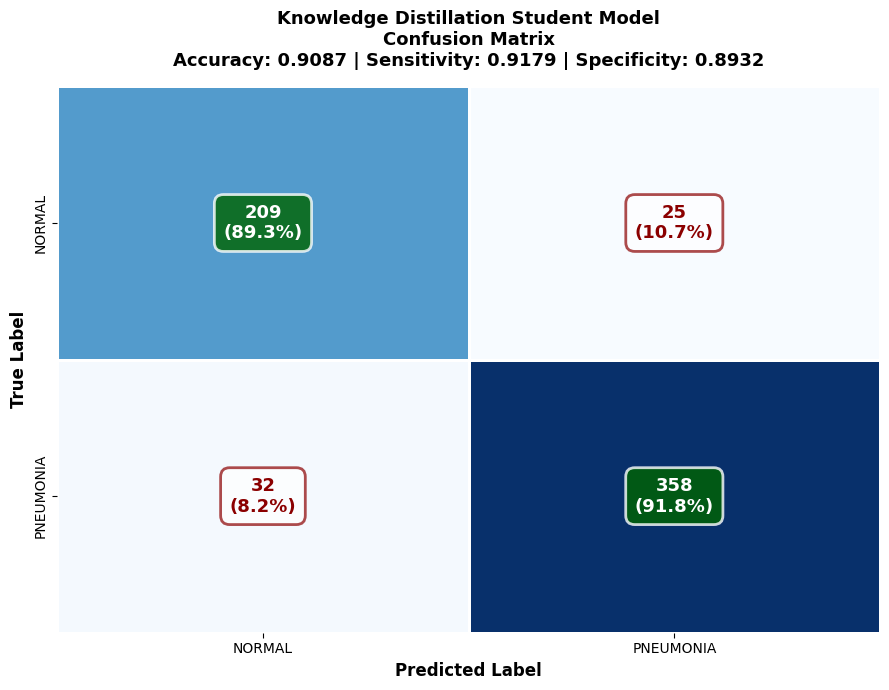

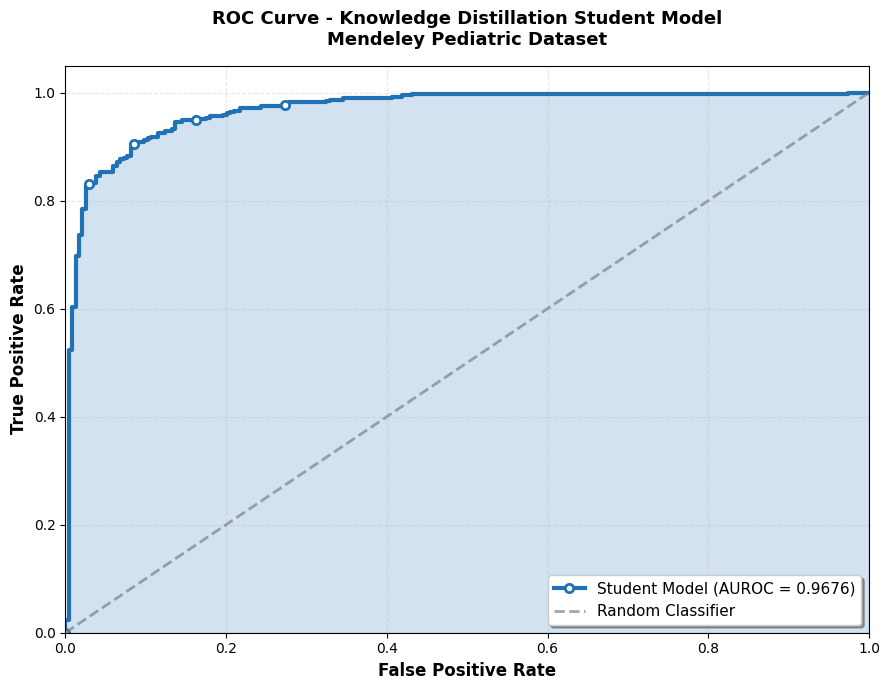

Visualizations complete


In [ ]:
# Confusion Matrix
plt.figure(figsize=(9, 7))

colors = ['#f7fbff', '#deebf7', '#c6dbef', '#6baed6', '#2171b5', '#08519c', '#08306b']
custom_cmap = sns.blend_palette(colors, as_cmap=True)

ax = sns.heatmap(cm, annot=False, fmt='d', cmap=custom_cmap,
                 xticklabels=class_names, yticklabels=class_names,
                 cbar=False, linewidths=2, linecolor='white')

for i in range(2):
    for j in range(2):
        value = cm[i, j]
        total = cm[i, :].sum()
        pct = value / total * 100 if total > 0 else 0

        if i == j:
            color = 'white'
            bbox_props = dict(boxstyle='round,pad=0.5', facecolor='darkgreen',
                            edgecolor='white', linewidth=2, alpha=0.8)
        else:
            color = 'darkred'
            bbox_props = dict(boxstyle='round,pad=0.5', facecolor='white',
                            edgecolor='darkred', linewidth=2, alpha=0.7)

        ax.text(j + 0.5, i + 0.5, f"{value}\n({pct:.1f}%)",
               ha='center', va='center', color=color,
               fontsize=13, fontweight='bold', bbox=bbox_props)

plt.title(f"Knowledge Distillation Student Model\nConfusion Matrix\n" +
          f"Accuracy: {accuracy:.4f} | Sensitivity: {sensitivity:.4f} | Specificity: {specificity:.4f}",
         fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Predicted Label", fontsize=12, fontweight='bold')
plt.ylabel("True Label", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(all_labels, all_predictions)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(9, 7))
plt.plot(fpr, tpr, color='#2171b5', linewidth=3,
         label=f'Student Model (AUROC = {roc_auc:.4f})', marker='o',
         markevery=20, markersize=6, markerfacecolor='white', markeredgewidth=2)
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=2,
         label='Random Classifier', alpha=0.7)
plt.fill_between(fpr, tpr, alpha=0.2, color='#2171b5')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
plt.title('ROC Curve - Knowledge Distillation Student Model\nMendeley Pediatric Dataset',
         fontsize=13, fontweight='bold', pad=15)
plt.legend(loc="lower right", fontsize=11, frameon=True, shadow=True)
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

print("Visualizations complete")

### **Evaluation with weighted accuracy and AUC**

In [ ]:
print("\n" + "="*70)
print("EVALUATING ALL EPOCHS TO FIND BEST MODEL")
print("="*70)

epoch_results = []

for epoch in range(1, EPOCHS + 1):
    epoch_path = os.path.join(OUTPUT_DIR, f"student_epoch_{epoch:02d}.keras")

    if not os.path.exists(epoch_path):
        continue

    epoch_model = tf.keras.models.load_model(epoch_path)

    all_predictions = []
    all_labels = []

    for images, labels in test_ds:
        predictions = epoch_model.predict(images, verbose=0)
        all_predictions.extend(predictions[:, 1])
        all_labels.extend(labels.numpy())

    all_predictions = np.array(all_predictions)
    all_labels = np.array(all_labels)
    predicted_classes = (all_predictions > 0.5).astype(int)

    accuracy = accuracy_score(all_labels, predicted_classes)
    auroc = roc_auc_score(all_labels, all_predictions)

    cm = confusion_matrix(all_labels, predicted_classes)
    tn, fp, fn, tp = cm.ravel()
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    balanced_acc = (sensitivity + specificity) / 2

    # Composite score: 40% AUROC + 30% Accuracy + 30% Balanced
    composite_score = 0.4 * auroc + 0.3 * accuracy + 0.3 * balanced_acc

    epoch_results.append({
        'epoch': epoch,
        'accuracy': accuracy,
        'auroc': auroc,
        'sensitivity': sensitivity,
        'specificity': specificity,
        'balanced_acc': balanced_acc,
        'composite_score': composite_score
    })

    print(f"\nEpoch {epoch:02d}: Acc={accuracy:.4f}, AUROC={auroc:.4f}, Sens={sensitivity:.4f}, Spec={specificity:.4f}, Balanced={balanced_acc:.4f}, Composite={composite_score:.4f}")

# Find best based on composite score
best_epoch = max(epoch_results, key=lambda x: x['composite_score'])

print("\n" + "="*70)
print("BEST EPOCH BASED ON COMPOSITE SCORE (40% AUROC + 30% Acc + 30% Balanced)")
print("="*70)
print(f"\nBest Epoch: {best_epoch['epoch']}")
print(f"Accuracy:      {best_epoch['accuracy']:.4f}")
print(f"AUROC:         {best_epoch['auroc']:.4f}")
print(f"Sensitivity:   {best_epoch['sensitivity']:.4f}")
print(f"Specificity:   {best_epoch['specificity']:.4f}")
print(f"Balanced Acc:  {best_epoch['balanced_acc']:.4f}")
print(f"Composite:     {best_epoch['composite_score']:.4f}")

best_model_path = os.path.join(OUTPUT_DIR, f"student_epoch_{best_epoch['epoch']:02d}.keras")
student_model = tf.keras.models.load_model(best_model_path)

student_model.save(os.path.join(OUTPUT_DIR, "student_model_final.keras"))
print(f"\nBest model saved as: student_model_final.keras")


EVALUATING ALL EPOCHS TO FIND BEST MODEL

Epoch 01: Acc=0.8702, AUROC=0.9380, Sens=0.9410, Spec=0.7521, Balanced=0.8466, Composite=0.8902

Epoch 02: Acc=0.9087, AUROC=0.9676, Sens=0.9179, Spec=0.8932, Balanced=0.9056, Composite=0.9313

Epoch 03: Acc=0.8654, AUROC=0.9734, Sens=0.9949, Spec=0.6496, Balanced=0.8222, Composite=0.8956

Epoch 04: Acc=0.7692, AUROC=0.9629, Sens=0.9974, Spec=0.3889, Balanced=0.6932, Composite=0.8239

Epoch 05: Acc=0.7724, AUROC=0.9824, Sens=0.9974, Spec=0.3974, Balanced=0.6974, Composite=0.8339

Epoch 06: Acc=0.7949, AUROC=0.9830, Sens=1.0000, Spec=0.4530, Balanced=0.7265, Composite=0.8496

Epoch 07: Acc=0.8590, AUROC=0.9797, Sens=0.9897, Spec=0.6410, Balanced=0.8154, Composite=0.8942

Epoch 08: Acc=0.8462, AUROC=0.9798, Sens=0.9897, Spec=0.6068, Balanced=0.7983, Composite=0.8853

Epoch 09: Acc=0.8526, AUROC=0.9773, Sens=0.9949, Spec=0.6154, Balanced=0.8051, Composite=0.8882

Epoch 10: Acc=0.8301, AUROC=0.9764, Sens=0.9923, Spec=0.5598, Balanced=0.7761, Compo

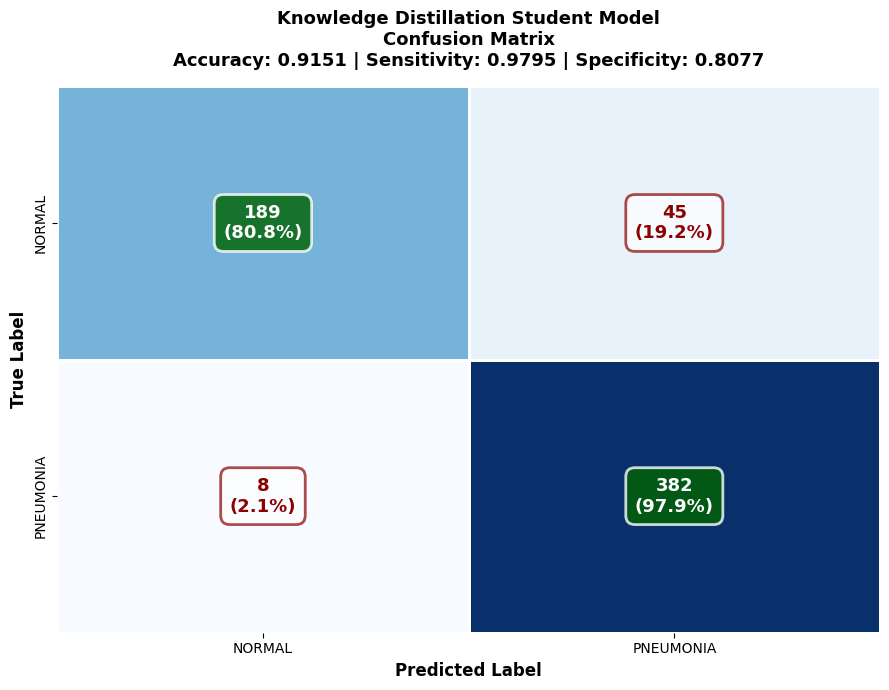

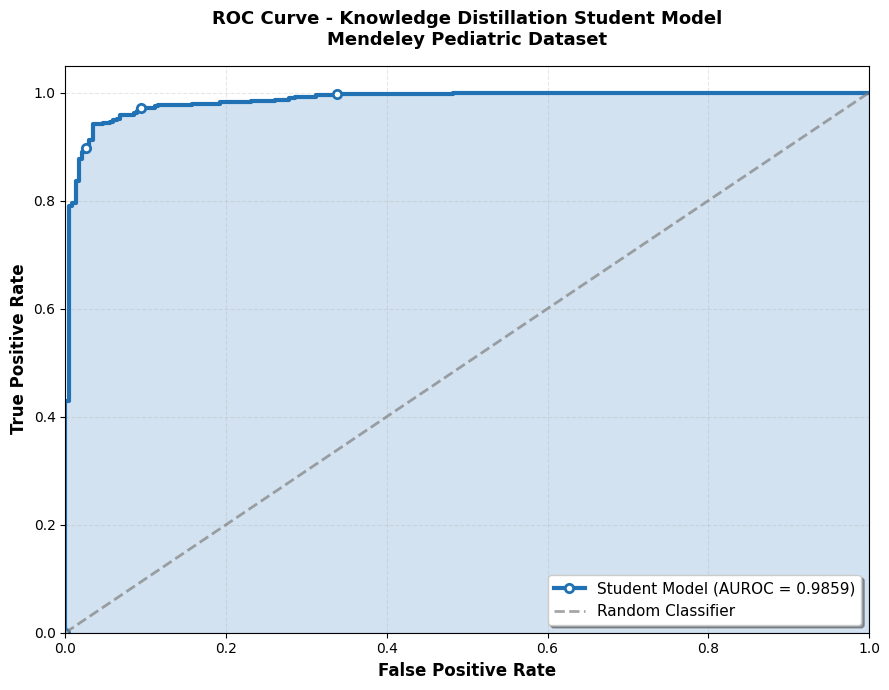

Visualizations complete


In [ ]:
# Confusion Matrix
plt.figure(figsize=(9, 7))

colors = ['#f7fbff', '#deebf7', '#c6dbef', '#6baed6', '#2171b5', '#08519c', '#08306b']
custom_cmap = sns.blend_palette(colors, as_cmap=True)

ax = sns.heatmap(cm, annot=False, fmt='d', cmap=custom_cmap,
                 xticklabels=class_names, yticklabels=class_names,
                 cbar=False, linewidths=2, linecolor='white')

for i in range(2):
    for j in range(2):
        value = cm[i, j]
        total = cm[i, :].sum()
        pct = value / total * 100 if total > 0 else 0

        if i == j:
            color = 'white'
            bbox_props = dict(boxstyle='round,pad=0.5', facecolor='darkgreen',
                            edgecolor='white', linewidth=2, alpha=0.8)
        else:
            color = 'darkred'
            bbox_props = dict(boxstyle='round,pad=0.5', facecolor='white',
                            edgecolor='darkred', linewidth=2, alpha=0.7)

        ax.text(j + 0.5, i + 0.5, f"{value}\n({pct:.1f}%)",
               ha='center', va='center', color=color,
               fontsize=13, fontweight='bold', bbox=bbox_props)

plt.title(f"Knowledge Distillation Student Model\nConfusion Matrix\n" +
          f"Accuracy: {accuracy:.4f} | Sensitivity: {sensitivity:.4f} | Specificity: {specificity:.4f}",
         fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Predicted Label", fontsize=12, fontweight='bold')
plt.ylabel("True Label", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(all_labels, all_predictions)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(9, 7))
plt.plot(fpr, tpr, color='#2171b5', linewidth=3,
         label=f'Student Model (AUROC = {roc_auc:.4f})', marker='o',
         markevery=20, markersize=6, markerfacecolor='white', markeredgewidth=2)
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=2,
         label='Random Classifier', alpha=0.7)
plt.fill_between(fpr, tpr, alpha=0.2, color='#2171b5')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
plt.title('ROC Curve - Knowledge Distillation Student Model\nMendeley Pediatric Dataset',
         fontsize=13, fontweight='bold', pad=15)
plt.legend(loc="lower right", fontsize=11, frameon=True, shadow=True)
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

print("Visualizations complete")

### **Xception- KD GridSearch**

In [ ]:
import tensorflow as tf
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (classification_report, confusion_matrix,
                            roc_auc_score, accuracy_score, roc_curve, auc,
                            precision_score, f1_score)

print("TensorFlow version:", tf.__version__)

# from google.colab import drive
# drive.mount('/content/drive')

import gc
tf.keras.backend.clear_session()
gc.collect()

TensorFlow version: 2.19.0


0

In [ ]:
MENDELEY_TRAIN_DIR = "/content/drive/MyDrive/chest_xray/train"
MENDELEY_TEST_DIR = "/content/drive/MyDrive/chest_xray/test"
TEACHER_PATH = "/content/drive/MyDrive/chest_xray/ensemble_models/Xception_weights-014-0.0046.keras"
OUTPUT_DIR_GRID = "/content/drive/MyDrive/chest_xray/Knowledge_Distillation_Xception_GridSearch"
os.makedirs(OUTPUT_DIR_GRID, exist_ok=True)

BATCH_SIZE = 16
IMG_SIZE = (299, 299)
EPOCHS = 15
SEED = 123

grid_configs = [
    {'temp': 3, 'alpha': 0.5, 'lr': 5e-5, 'name': 'T3_A05'},
    {'temp': 4, 'alpha': 0.4, 'lr': 5e-5, 'name': 'T4_A04'},
    {'temp': 4, 'alpha': 0.6, 'lr': 5e-5, 'name': 'T4_A06'},
    {'temp': 5, 'alpha': 0.5, 'lr': 5e-5, 'name': 'T5_A05'},
]

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Grid search configuration set for Xception on Mendeley")
print(f"Testing {len(grid_configs)} configurations")
for config in grid_configs:
    print(f"  {config['name']}: T={config['temp']}, Alpha={config['alpha']}, LR={config['lr']}")

Grid search configuration set for Xception on Mendeley
Testing 4 configurations
  T3_A05: T=3, Alpha=0.5, LR=5e-05
  T4_A04: T=4, Alpha=0.4, LR=5e-05
  T4_A06: T=4, Alpha=0.6, LR=5e-05
  T5_A05: T=5, Alpha=0.5, LR=5e-05


In [ ]:
print("Preparing Mendeley dataset...")

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    MENDELEY_TRAIN_DIR,
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset='training',
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    MENDELEY_TRAIN_DIR,
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset='validation',
    shuffle=True,
    seed=SEED
)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    MENDELEY_TEST_DIR,
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = test_ds.class_names
print(f"Classes: {class_names}")
print("Data preparation complete")

Preparing Mendeley dataset...
Found 5232 files belonging to 2 classes.
Using 4186 files for training.
Found 5232 files belonging to 2 classes.
Using 1046 files for validation.
Found 624 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']
Data preparation complete


In [ ]:
def count_samples(directory):
    counts = {}
    for cls in os.listdir(directory):
        cls_path = os.path.join(directory, cls)
        if os.path.isdir(cls_path):
            counts[cls] = len([f for f in os.listdir(cls_path)
                             if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
    return counts

train_counts = count_samples(MENDELEY_TRAIN_DIR)
print(f"Training samples: {train_counts}")

total = sum(train_counts.values())
class_weights = {i: total / (len(train_counts) * count)
                for i, (_, count) in enumerate(sorted(train_counts.items()))}

print(f"Class weights: {class_weights}")
print(f"NORMAL weight: {class_weights[0]:.3f}, PNEUMONIA weight: {class_weights[1]:.3f}")

Training samples: {'NORMAL': 1349, 'PNEUMONIA': 3883}
Class weights: {0: 1.939214232765011, 1: 0.6737058975019315}
NORMAL weight: 1.939, PNEUMONIA weight: 0.674


In [ ]:
print("Loading teacher model (Xception)...")

def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fn(y_true, y_pred):
        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1.0 - epsilon)

        y_true = tf.cast(y_true, tf.float32)
        cross_entropy = -y_true * tf.math.log(y_pred)
        focal_weight = alpha * tf.pow(1 - y_pred, gamma)
        loss = focal_weight * cross_entropy

        return tf.reduce_mean(loss)
    return focal_loss_fn

teacher_model = tf.keras.models.load_model(
    TEACHER_PATH,
    custom_objects={'focal_loss_fn': focal_loss(gamma=2.0, alpha=0.25)}
)
teacher_model.trainable = False

print("Teacher model loaded successfully")
print(f"Teacher output shape: {teacher_model.output_shape}")

Loading teacher model (Xception)...
Teacher model loaded successfully
Teacher output shape: (None, 2)


**Block 7: Distillation Loss Definition**

In [ ]:
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fn(y_true, y_pred):
        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1.0 - epsilon)

        cross_entropy = -y_true * tf.math.log(y_pred)
        focal_weight = alpha * tf.pow(1 - y_pred, gamma)
        loss = focal_weight * cross_entropy

        return tf.reduce_mean(tf.reduce_sum(loss, axis=-1))
    return focal_loss_fn

class DistillationLoss:
    def __init__(self, temperature=4, alpha=0.5):
        self.temperature = temperature
        self.alpha = alpha
        self.focal_loss_fn = focal_loss(gamma=2.0, alpha=0.25)
        self.bce = tf.keras.losses.BinaryCrossentropy()

    def __call__(self, y_true, student_pred, teacher_pred):
        y_true_int = tf.cast(tf.squeeze(y_true), tf.int32)
        y_true_one_hot = tf.one_hot(y_true_int, depth=2)

        student_loss = self.focal_loss_fn(y_true_one_hot, student_pred)

        teacher_soft = tf.nn.sigmoid(teacher_pred / self.temperature)
        student_soft = tf.nn.sigmoid(student_pred / self.temperature)

        distillation_loss = self.bce(teacher_soft, student_soft)

        total_loss = self.alpha * distillation_loss + (1 - self.alpha) * student_loss
        return total_loss

print("Distillation loss defined")

Distillation loss defined


**Block 8: Grid Search Training Loop**

In [ ]:
print("Starting grid search for Xception...")

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Input, Rescaling
from tensorflow.keras.models import Model

grid_results = []

for config_idx, config in enumerate(grid_configs):
    print(f"\n{'='*70}")
    print(f"GRID SEARCH {config_idx + 1}/{len(grid_configs)}: {config['name']}")
    print(f"Temperature={config['temp']}, Alpha={config['alpha']}, LR={config['lr']}")
    print(f"{'='*70}")

    tf.keras.backend.clear_session()
    gc.collect()

    student_inputs = Input(shape=(299, 299, 3))
    student_x = Rescaling(1.0 / 255)(student_inputs)
    student_x = tf.keras.applications.mobilenet_v2.preprocess_input(student_x * 255.0)

    student_base = MobileNetV2(include_top=False, weights='imagenet', input_tensor=student_x)
    student_x = student_base.output
    student_x = GlobalAveragePooling2D()(student_x)
    student_x = Dense(128, activation='relu')(student_x)
    student_x = Dropout(0.3)(student_x)
    student_outputs = Dense(2, activation='softmax')(student_x)

    student_model_grid = Model(inputs=student_inputs, outputs=student_outputs)

    optimizer_grid = tf.keras.optimizers.Adam(learning_rate=config['lr'])
    distill_loss_fn_grid = DistillationLoss(temperature=config['temp'], alpha=config['alpha'])

    config_dir = os.path.join(OUTPUT_DIR_GRID, config['name'])
    os.makedirs(config_dir, exist_ok=True)

    train_loss_metric = tf.keras.metrics.Mean()
    train_acc_metric = tf.keras.metrics.BinaryAccuracy()
    val_loss_metric = tf.keras.metrics.Mean()
    val_acc_metric = tf.keras.metrics.BinaryAccuracy()

    best_val_acc = 0.0
    patience_counter = 0

    for epoch in range(EPOCHS):
        print(f"\nEpoch {epoch + 1}/{EPOCHS}")

        train_loss_metric.reset_state()
        train_acc_metric.reset_state()

        for images, labels in train_ds:
            sample_weights = tf.where(labels == 0, class_weights[0], class_weights[1])
            teacher_predictions = teacher_model(images, training=False)

            with tf.GradientTape() as tape:
                student_predictions = student_model_grid(images, training=True)
                loss = distill_loss_fn_grid(labels, student_predictions, teacher_predictions)
                weighted_loss = loss * tf.reduce_mean(sample_weights)

            gradients = tape.gradient(weighted_loss, student_model_grid.trainable_variables)
            optimizer_grid.apply_gradients(zip(gradients, student_model_grid.trainable_variables))

            train_loss_metric.update_state(weighted_loss)
            train_acc_metric.update_state(labels, tf.argmax(student_predictions, axis=1))

        val_loss_metric.reset_state()
        val_acc_metric.reset_state()

        for images, labels in val_ds:
            teacher_predictions = teacher_model(images, training=False)
            student_predictions = student_model_grid(images, training=False)

            val_loss = distill_loss_fn_grid(labels, student_predictions, teacher_predictions)
            val_loss_metric.update_state(val_loss)
            val_acc_metric.update_state(labels, tf.argmax(student_predictions, axis=1))

        train_loss = train_loss_metric.result().numpy()
        train_acc = train_acc_metric.result().numpy()
        val_loss = val_loss_metric.result().numpy()
        val_acc = val_acc_metric.result().numpy()

        print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
        print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

        student_model_grid.save(os.path.join(config_dir, f"student_epoch_{epoch+1:02d}.keras"))

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            patience_counter = 0
            print(f"Saved epoch {epoch+1}")
        else:
            patience_counter += 1
            if patience_counter >= 5:
                print("Early stopping")
                break

    grid_results.append({
        'config': config,
        'config_dir': config_dir
    })

print("\n" + "="*70)
print("GRID SEARCH TRAINING COMPLETED")
print("="*70)

Starting grid search for Xception...

GRID SEARCH 1/4: T3_A05
Temperature=3, Alpha=0.5, LR=5e-05


/tmp/ipython-input-1973915950.py:22: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  student_base = MobileNetV2(include_top=False, weights='imagenet', input_tensor=student_x)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

Epoch 1/15
Train Loss: 0.3578, Train Acc: 0.9195
Val Loss: 0.3651, Val Acc: 0.6836
Saved epoch 1

Epoch 2/15
Train Loss: 0.3531, Train Acc: 0.9752
Val Loss: 0.3543, Val Acc: 0.9111
Saved epoch 2

Epoch 3/15
Train Loss: 0.3521, Train Acc: 0.9866
Val Loss: 0.3535, Val Acc: 0.9168
Saved epoch 3

Epoch 4/15
Train Loss: 0.3517, Train Acc: 0.9888
Val Loss: 0.3562, Val Acc: 0.8815

Epoch 5/15
Train Loss: 0.3513, Train Acc: 0.9964
Val Loss: 0.3609, Val Acc: 0.8327

Epoch 6/15
Train Loss: 0.3510, Train Acc: 0.9974
Val Loss: 0.3644, Val Acc: 0.8212

Epoch 7/15
Train Loss: 0.3510, Train Acc: 0.9990
Val Loss: 0.3685, Val Acc: 0.8155

Epoch 8/15
Train Loss: 0.3509, Train Acc: 0.9974
Val Loss: 0.3649, Val Acc: 0.8308
Early stopping

GRID SEARCH 2/4: T4_A04
Temperature=4, Alpha=0.4, LR=5e-05

Epoch 1/15
Train Loss: 0.2873, Train Acc: 0.9391
Val Loss: 0.2986, Val Acc: 0.8021
Saved epoch 1

Epoch 2/15
Train Loss: 0.2828, Train Acc: 0.9768
Val Loss: 0.29

**Block 9: Grid Search Evaluation**

In [ ]:
print("\n" + "="*70)
print("EVALUATING ALL GRID SEARCH CONFIGURATIONS")
print("="*70)

all_config_results = []

for result in grid_results:
    config = result['config']
    config_dir = result['config_dir']

    print(f"\n{'='*70}")
    print(f"Evaluating: {config['name']}")
    print(f"{'='*70}")

    epoch_results = []

    for epoch in range(1, EPOCHS + 1):
        epoch_path = os.path.join(config_dir, f"student_epoch_{epoch:02d}.keras")

        if not os.path.exists(epoch_path):
            continue

        epoch_model = tf.keras.models.load_model(epoch_path)

        all_predictions = []
        all_labels = []

        for images, labels in test_ds:
            predictions = epoch_model.predict(images, verbose=0)
            all_predictions.extend(predictions[:, 1])
            all_labels.extend(labels.numpy())

        all_predictions = np.array(all_predictions)
        all_labels = np.array(all_labels)
        predicted_classes = (all_predictions > 0.5).astype(int)

        accuracy = accuracy_score(all_labels, predicted_classes)
        auroc = roc_auc_score(all_labels, all_predictions)

        cm = confusion_matrix(all_labels, predicted_classes)
        tn, fp, fn, tp = cm.ravel()
        sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

        balanced_acc = (sensitivity + specificity) / 2
        sens_spec_diff = abs(sensitivity - specificity)
        balance_penalty = 1.0 - (sens_spec_diff * 0.5)

        composite_score = (0.3 * auroc +
                          0.3 * accuracy +
                          0.4 * balanced_acc * balance_penalty)

        epoch_results.append({
            'epoch': epoch,
            'accuracy': accuracy,
            'auroc': auroc,
            'sensitivity': sensitivity,
            'specificity': specificity,
            'balanced_acc': balanced_acc,
            'sens_spec_diff': sens_spec_diff,
            'composite_score': composite_score
        })

        print(f"Epoch {epoch:02d}: Acc={accuracy:.4f}, AUROC={auroc:.4f}, " +
              f"Sens={sensitivity:.4f}, Spec={specificity:.4f}, " +
              f"Diff={sens_spec_diff:.4f}, Score={composite_score:.4f}")

    if epoch_results:
        best_epoch = max(epoch_results, key=lambda x: x['composite_score'])
        best_epoch['config_name'] = config['name']
        best_epoch['config'] = config
        best_epoch['config_dir'] = config_dir

        all_config_results.append(best_epoch)

        print(f"\nBest for {config['name']}: Epoch {best_epoch['epoch']}, Score={best_epoch['composite_score']:.4f}")

overall_best = max(all_config_results, key=lambda x: x['composite_score'])

print("\n" + "="*70)
print("BEST GRID SEARCH MODEL")
print("="*70)
print(f"\nConfiguration: {overall_best['config_name']}")
print(f"Temperature: {overall_best['config']['temp']}")
print(f"Alpha: {overall_best['config']['alpha']}")
print(f"Epoch: {overall_best['epoch']}")
print(f"\nAccuracy:       {overall_best['accuracy']:.4f}")
print(f"AUROC:          {overall_best['auroc']:.4f}")
print(f"Sensitivity:    {overall_best['sensitivity']:.4f}")
print(f"Specificity:    {overall_best['specificity']:.4f}")
print(f"Balanced Acc:   {overall_best['balanced_acc']:.4f}")
print(f"Sens/Spec Diff: {overall_best['sens_spec_diff']:.4f}")

best_model_path = os.path.join(overall_best['config_dir'], f"student_epoch_{overall_best['epoch']:02d}.keras")
final_model = tf.keras.models.load_model(best_model_path)
final_model.save(os.path.join(OUTPUT_DIR_GRID, "student_model_best_grid.keras"))

print(f"\nBest model saved as: student_model_best_grid.keras")
print("="*70)


EVALUATING ALL GRID SEARCH CONFIGURATIONS

Evaluating: T3_A05
Epoch 01: Acc=0.7516, AUROC=0.8950, Sens=0.6333, Spec=0.9487, Diff=0.3154, Score=0.7605
Epoch 02: Acc=0.8365, AUROC=0.9150, Sens=0.9308, Spec=0.6795, Diff=0.2513, Score=0.8071
Epoch 03: Acc=0.7740, AUROC=0.9529, Sens=0.9974, Spec=0.4017, Diff=0.5957, Score=0.7145
Epoch 04: Acc=0.7196, AUROC=0.9564, Sens=1.0000, Spec=0.2521, Diff=0.7479, Score=0.6596
Epoch 05: Acc=0.6779, AUROC=0.9491, Sens=1.0000, Spec=0.1410, Diff=0.8590, Score=0.6183
Epoch 06: Acc=0.6490, AUROC=0.9425, Sens=1.0000, Spec=0.0641, Diff=0.9359, Score=0.5907
Epoch 07: Acc=0.6474, AUROC=0.8916, Sens=1.0000, Spec=0.0598, Diff=0.9402, Score=0.5740
Epoch 08: Acc=0.6587, AUROC=0.9069, Sens=1.0000, Spec=0.0897, Diff=0.9103, Score=0.5884

Best for T3_A05: Epoch 2, Score=0.8071

Evaluating: T4_A04
Epoch 01: Acc=0.6522, AUROC=0.9235, Sens=1.0000, Spec=0.0726, Diff=0.9274, Score=0.5878
Epoch 02: Acc=0.6731, AUROC=0.9585, Sens=1.0000, Spec=0.1282, Diff=0.8718, Score=0.61

**Block 10: Final Evaluation**

In [ ]:
student_model = tf.keras.models.load_model(os.path.join(OUTPUT_DIR_GRID, "student_model_best_grid.keras"))

all_predictions = []
all_labels = []

for images, labels in test_ds:
    predictions = student_model.predict(images, verbose=0)
    all_predictions.extend(predictions[:, 1])
    all_labels.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)
predicted_classes = (all_predictions > 0.5).astype(int)

accuracy = accuracy_score(all_labels, predicted_classes)
auroc = roc_auc_score(all_labels, all_predictions)

cm = confusion_matrix(all_labels, predicted_classes)
tn, fp, fn, tp = cm.ravel()

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
precision = precision_score(all_labels, predicted_classes)
f1 = f1_score(all_labels, predicted_classes)

student_size_mb = os.path.getsize(os.path.join(OUTPUT_DIR_GRID, "student_model_best_grid.keras")) / (1024 * 1024)

print("\n" + "="*70)
print("FINAL EVALUATION - BEST GRID SEARCH MODEL")
print("="*70)
print(f"\nAccuracy:      {accuracy:.4f}")
print(f"AUROC:         {auroc:.4f}")
print(f"Sensitivity:   {sensitivity:.4f}")
print(f"Specificity:   {specificity:.4f}")
print(f"Precision:     {precision:.4f}")
print(f"F1-Score:      {f1:.4f}")
print(f"Model Size:    {student_size_mb:.2f} MB")

print("\nClassification Report:")
print(classification_report(all_labels, predicted_classes, target_names=class_names, digits=4))

print("\nConfusion Matrix:")
print(cm)
print(f"TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")


FINAL EVALUATION - BEST GRID SEARCH MODEL

Accuracy:      0.8365
AUROC:         0.9150
Sensitivity:   0.9308
Specificity:   0.6795
Precision:     0.8288
F1-Score:      0.8768
Model Size:    9.79 MB

Classification Report:
              precision    recall  f1-score   support

      NORMAL     0.8548    0.6795    0.7571       234
   PNEUMONIA     0.8288    0.9308    0.8768       390

    accuracy                         0.8365       624
   macro avg     0.8418    0.8051    0.8170       624
weighted avg     0.8385    0.8365    0.8319       624


Confusion Matrix:
[[159  75]
 [ 27 363]]
TN: 159, FP: 75, FN: 27, TP: 363


**Block 11: Confusion Matrix Visualization**

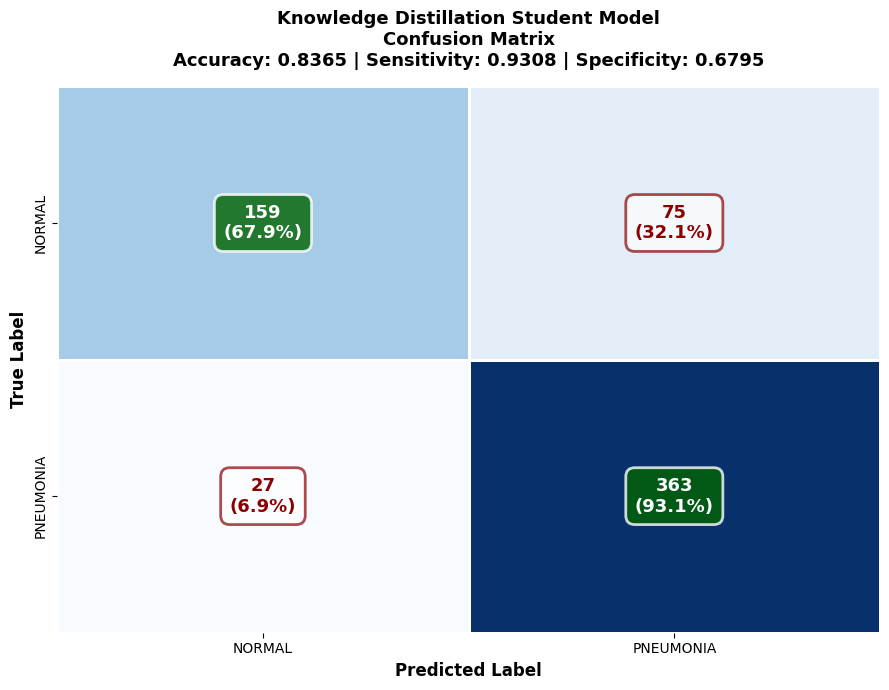

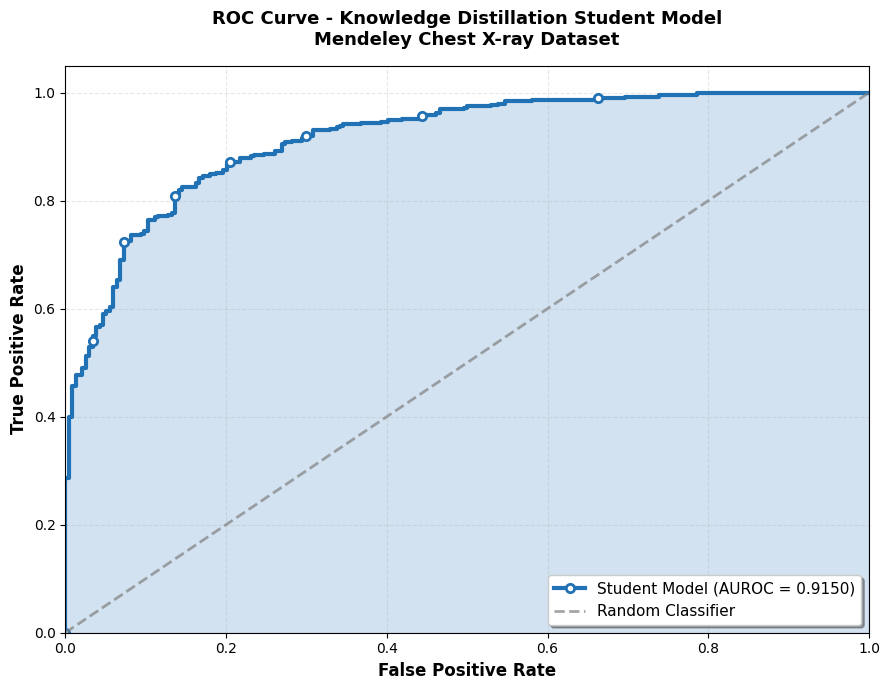

In [ ]:
plt.figure(figsize=(9, 7))
cm = confusion_matrix(all_labels, predicted_classes)

colors = ['#f7fbff', '#deebf7', '#c6dbef', '#6baed6', '#2171b5', '#08519c', '#08306b']
custom_cmap = sns.blend_palette(colors, as_cmap=True)

ax = sns.heatmap(cm, annot=False, fmt='d', cmap=custom_cmap,
                 xticklabels=class_names, yticklabels=class_names,
                 cbar=False, linewidths=2, linecolor='white')

for i in range(2):
    for j in range(2):
        value = cm[i, j]
        total = cm[i, :].sum()
        pct = value / total * 100 if total > 0 else 0

        if i == j:
            color = 'white'
            bbox_props = dict(boxstyle='round,pad=0.5', facecolor='darkgreen',
                            edgecolor='white', linewidth=2, alpha=0.8)
        else:
            color = 'darkred'
            bbox_props = dict(boxstyle='round,pad=0.5', facecolor='white',
                            edgecolor='darkred', linewidth=2, alpha=0.7)

        ax.text(j + 0.5, i + 0.5, f"{value}\n({pct:.1f}%)",
               ha='center', va='center', color=color,
               fontsize=13, fontweight='bold', bbox=bbox_props)

plt.title(f"Knowledge Distillation Student Model\nConfusion Matrix\n" +
          f"Accuracy: {accuracy:.4f} | Sensitivity: {sensitivity:.4f} | Specificity: {specificity:.4f}",
         fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Predicted Label", fontsize=12, fontweight='bold')
plt.ylabel("True Label", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(all_labels, all_predictions)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(9, 7))
plt.plot(fpr, tpr, color='#2171b5', linewidth=3,
         label=f'Student Model (AUROC = {roc_auc:.4f})', marker='o',
         markevery=20, markersize=6, markerfacecolor='white', markeredgewidth=2)
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=2,
         label='Random Classifier', alpha=0.7)
plt.fill_between(fpr, tpr, alpha=0.2, color='#2171b5')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
plt.title('ROC Curve - Knowledge Distillation Student Model\nMendeley Chest X-ray Dataset',
         fontsize=13, fontweight='bold', pad=15)
plt.legend(loc="lower right", fontsize=11, frameon=True, shadow=True)
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

#### **Nuclear Ensemble**

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.9/400.9 kB 6.8 MB/s eta 0:00:00


In [ ]:
import tensorflow as tf
import numpy as np
import os
import optuna
from functools import partial
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (classification_report, confusion_matrix,
                            roc_auc_score, accuracy_score, roc_curve, auc,
                            precision_score, f1_score)

print("TensorFlow version:", tf.__version__)

# from google.colab import drive
# drive.mount('/content/drive')

import gc
tf.keras.backend.clear_session()
gc.collect()

print("Setup complete")

TensorFlow version: 2.19.0
Setup complete


In [ ]:
MENDELEY_TRAIN_DIR = "/content/drive/MyDrive/chest_xray/train"
MENDELEY_TEST_DIR = "/content/drive/MyDrive/chest_xray/test"
OUTPUT_DIR = "/content/drive/MyDrive/chest_xray/Nuclear_Ensemble_Distillation"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Original ensemble components
BASE_MODEL_DIR = "/content/drive/MyDrive/chest_xray"
TEACHER_META_LEARNER = os.path.join(BASE_MODEL_DIR, "nuclear_ensemble_meta_learner.keras")
TEACHER_OPTIMAL_WEIGHTS = os.path.join(BASE_MODEL_DIR, "Nuclear_ensemble_optimal_weights.npy")

# Teacher base models paths
teacher_base_paths = [
    os.path.join(BASE_MODEL_DIR, "base_model_0.keras"),
    os.path.join(BASE_MODEL_DIR, "base_model_1.keras"),
    os.path.join(BASE_MODEL_DIR, "base_model_2.keras"),
    os.path.join(BASE_MODEL_DIR, "base_model_3.keras"),
    os.path.join(BASE_MODEL_DIR, "base_model_4.keras")
]

# Student model paths (Xception already trained, others will be created)
XCEPTION_STUDENT_PATH = "/content/drive/MyDrive/chest_xray/Knowledge_Distillation_Xception_Final/student_model_final.keras"

student_model_paths = [
    os.path.join(OUTPUT_DIR, "student_ResNet50.keras"),
    os.path.join(OUTPUT_DIR, "student_DenseNet121.keras"),
    os.path.join(OUTPUT_DIR, "student_InceptionV3.keras"),
    XCEPTION_STUDENT_PATH,  # Pre-trained - DO NOT override
    os.path.join(OUTPUT_DIR, "student_MobileNetV2.keras")
]

# Model configurations with proper input sizes
model_configs = [
    {'name': 'ResNet50', 'teacher_idx': 0, 'input_size': (224, 224)},
    {'name': 'DenseNet121', 'teacher_idx': 1, 'input_size': (224, 224)},
    {'name': 'InceptionV3', 'teacher_idx': 2, 'input_size': (299, 299)},
    {'name': 'Xception', 'teacher_idx': 3, 'input_size': (299, 299)},
    {'name': 'MobileNetV2', 'teacher_idx': 4, 'input_size': (224, 224)}
]

BATCH_SIZE = 16
IMG_SIZE = (224, 224)
DISTILL_EPOCHS = 10
SEED = 123

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Configuration complete")
print(f"Output directory: {OUTPUT_DIR}")
print(f"Xception student path (pre-trained): {XCEPTION_STUDENT_PATH}")

Configuration complete
Output directory: /content/drive/MyDrive/chest_xray/Nuclear_Ensemble_Distillation
Xception student path (pre-trained): /content/drive/MyDrive/chest_xray/Knowledge_Distillation_Xception_Final/student_model_final.keras


In [ ]:
print("\nPreparing Mendeley dataset...")

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    MENDELEY_TRAIN_DIR,
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset='training',
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    MENDELEY_TRAIN_DIR,
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset='validation',
    shuffle=True,
    seed=SEED
)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    MENDELEY_TEST_DIR,
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = test_ds.class_names
print(f"Classes: {class_names}")
print("Data loaded successfully")


Preparing Mendeley dataset...
Found 5232 files belonging to 2 classes.
Using 4186 files for training.
Found 5232 files belonging to 2 classes.
Using 1046 files for validation.
Found 624 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']
Data loaded successfully


In [ ]:
print("\n" + "="*70)
print("LOADING TEACHER ENSEMBLE")
print("="*70)

# Focal loss for loading saved models
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fn(y_true, y_pred):
        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1.0 - epsilon)
        y_true = tf.cast(y_true, tf.float32)
        cross_entropy = -y_true * tf.math.log(y_pred)
        focal_weight = alpha * tf.pow(1 - y_pred, gamma)
        loss = focal_weight * cross_entropy
        return tf.reduce_mean(loss)
    return focal_loss_fn

# Load teacher base models
teacher_base_models = []
for i, path in enumerate(teacher_base_paths):
    try:
        model = tf.keras.models.load_model(
            path,
            custom_objects={'focal_loss_fn': focal_loss(gamma=2.0, alpha=0.25)}
        )
        model.trainable = False
        teacher_base_models.append(model)
        print(f"Loaded teacher {model_configs[i]['name']}")
    except Exception as e:
        print(f"Error loading {model_configs[i]['name']}: {e}")
        teacher_base_models.append(None)

print(f"\nTotal teacher models loaded: {len([m for m in teacher_base_models if m is not None])}/5")


LOADING TEACHER ENSEMBLE
Loaded teacher ResNet50
Loaded teacher DenseNet121
Loaded teacher InceptionV3
Loaded teacher Xception
Loaded teacher MobileNetV2

Total teacher models loaded: 5/5


In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Input, Rescaling
from tensorflow.keras.models import Model

def create_student_model(input_size=(224, 224)):
    """Create a MobileNetV2-based student model"""
    student_inputs = Input(shape=(input_size[0], input_size[1], 3))
    student_x = Rescaling(1.0 / 255)(student_inputs)
    student_x = tf.keras.applications.mobilenet_v2.preprocess_input(student_x * 255.0)

    student_base = MobileNetV2(include_top=False, weights='imagenet', input_tensor=student_x)
    student_x = student_base.output
    student_x = GlobalAveragePooling2D()(student_x)
    student_x = Dense(128, activation='relu')(student_x)
    student_x = Dropout(0.3)(student_x)
    student_outputs = Dense(2, activation='softmax')(student_x)

    model = Model(inputs=student_inputs, outputs=student_outputs)
    return model

print("Student architecture factory defined")

Student architecture factory defined


In [ ]:
def focal_loss_distill(gamma=2.0, alpha=0.25):
    def focal_loss_fn(y_true, y_pred):
        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1.0 - epsilon)
        cross_entropy = -y_true * tf.math.log(y_pred)
        focal_weight = alpha * tf.pow(1 - y_pred, gamma)
        loss = focal_weight * cross_entropy
        return tf.reduce_mean(tf.reduce_sum(loss, axis=-1))
    return focal_loss_fn

class SimpleDistillationLoss:
    def __init__(self, temperature=4, alpha=0.5):
        self.temperature = temperature
        self.alpha = alpha
        self.focal_loss_fn = focal_loss_distill(gamma=2.0, alpha=0.25)
        self.soft_loss = tf.keras.losses.CategoricalCrossentropy()

    def __call__(self, y_true, student_pred, teacher_pred):
        y_true_int = tf.cast(tf.squeeze(y_true), tf.int32)
        y_true_one_hot = tf.one_hot(y_true_int, depth=2)

        student_loss = self.focal_loss_fn(y_true_one_hot, student_pred)

        teacher_soft = tf.nn.softmax(teacher_pred / self.temperature)
        student_soft = tf.nn.softmax(student_pred / self.temperature)

        distillation_loss = self.soft_loss(teacher_soft, student_soft)

        total_loss = self.alpha * distillation_loss + (1 - self.alpha) * student_loss
        return total_loss

print("Distillation loss defined")

Distillation loss defined


In [ ]:
print("\n" + "="*70)
print("TRAINING INDIVIDUAL STUDENT MODELS")
print("="*70)

for i, config in enumerate(model_configs):
    # Skip Xception (index 3)
    if i == 3:
        print(f"\nSkipping {config['name']} - using pre-trained student from:")
        print(f"  {XCEPTION_STUDENT_PATH}")
        continue

    teacher_model = teacher_base_models[config['teacher_idx']]
    student_save_path = student_model_paths[i]

    if teacher_model is None:
        print(f"\nSkipping {config['name']} - teacher not loaded")
        continue

    print(f"\n{'='*70}")
    print(f"TRAINING STUDENT FOR {config['name']}")
    print(f"{'='*70}")

    # Create student with proper input size
    student_model = create_student_model(input_size=config['input_size'])

    # Training setup
    optimizer = tf.keras.optimizers.Adam(learning_rate=5e-5)
    distill_loss_fn = SimpleDistillationLoss(temperature=4, alpha=0.5)

    print(f"Training {config['name']} student for {DISTILL_EPOCHS} epochs...")
    print(f"Student input size: {config['input_size']}")
    print(f"Teacher input size: {teacher_model.input_shape[1:3]}")

    for epoch in range(DISTILL_EPOCHS):
        train_loss_metric = tf.keras.metrics.Mean()

        for images, labels in train_ds:
            # Prepare images for teacher (teacher expects specific size)
            teacher_input_size = teacher_model.input_shape[1:3]
            if teacher_input_size != IMG_SIZE:
                teacher_images = tf.image.resize(images, teacher_input_size)
            else:
                teacher_images = images

            # Prepare images for student (student expects its own size)
            if config['input_size'] != IMG_SIZE:
                student_images = tf.image.resize(images, config['input_size'])
            else:
                student_images = images

            teacher_predictions = teacher_model(teacher_images, training=False)

            with tf.GradientTape() as tape:
                student_predictions = student_model(student_images, training=True)
                loss = distill_loss_fn(labels, student_predictions, teacher_predictions)

            gradients = tape.gradient(loss, student_model.trainable_variables)
            optimizer.apply_gradients(zip(gradients, student_model.trainable_variables))

            train_loss_metric.update_state(loss)

        if (epoch + 1) % 3 == 0 or epoch == 0:
            print(f"  Epoch {epoch+1}/{DISTILL_EPOCHS} - Loss: {train_loss_metric.result().numpy():.4f}")

    # Save student model
    student_model.save(student_save_path)
    print(f"Saved to: {student_save_path}")

    # Clear memory
    del student_model
    tf.keras.backend.clear_session()
    gc.collect()

print("\n" + "="*70)
print("ALL INDIVIDUAL STUDENTS TRAINED")
print("="*70)


TRAINING INDIVIDUAL STUDENT MODELS

TRAINING STUDENT FOR ResNet50


/tmp/ipython-input-2091877832.py:11: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  student_base = MobileNetV2(include_top=False, weights='imagenet', input_tensor=student_x)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training ResNet50 student for 10 epochs...
Student input size: (224, 224)
Teacher input size: (224, 224)
  Epoch 1/10 - Loss: 0.3519
  Epoch 3/10 - Loss: 0.3468
  Epoch 6/10 - Loss: 0.3459
  Epoch 9/10 - Loss: 0.3458
Saved to: /content/drive/MyDrive/chest_xray/Nuclear_Ensemble_Distillation/student_ResNet50.keras

TRAINING STUDENT FOR DenseNet121
Training DenseNet121 student for 10 epochs...
Student input size: (224, 224)
Teacher input size: (224, 224)
  Epoch 1/10 - Loss: 0.3539
  Epoch 3/10 - Loss: 0.3490
  Epoch 6/10 - Loss: 0.3481
  Epoch 9/10 - Loss: 0.3479
Saved to: /content/drive/MyDrive/chest_xray/Nuclear_Ensemble_Distillation/student_DenseNet121.keras

TRAINING STUDENT FOR InceptionV3
Training InceptionV3 student for 10 epochs...
Student input size: (299, 299)
Teacher input size: (299, 299)
  Epoch 1/10 - Loss: 0.3514
  Epoch 3/10 - Loss: 0.3467


In [ ]:
print("\n" + "="*70)
print("LOADING ALL STUDENT MODELS")
print("="*70)

student_models = []
for i, (path, config) in enumerate(zip(student_model_paths, model_configs)):
    try:
        model = tf.keras.models.load_model(path)
        model.trainable = False
        student_models.append(model)
        print(f"Loaded student {config['name']} from: {path}")
        print(f"  Input shape: {model.input_shape}")
    except Exception as e:
        print(f"Error loading student {config['name']}: {e}")
        student_models.append(None)

print(f"\nTotal student models loaded: {len([m for m in student_models if m is not None])}/5")


LOADING ALL STUDENT MODELS
Loaded student ResNet50 from: /content/drive/MyDrive/chest_xray/Nuclear_Ensemble_Distillation/student_ResNet50.keras
  Input shape: (None, 224, 224, 3)
Loaded student DenseNet121 from: /content/drive/MyDrive/chest_xray/Nuclear_Ensemble_Distillation/student_DenseNet121.keras
  Input shape: (None, 224, 224, 3)
Loaded student InceptionV3 from: /content/drive/MyDrive/chest_xray/Nuclear_Ensemble_Distillation/student_InceptionV3.keras
  Input shape: (None, 224, 224, 3)
Loaded student Xception from: /content/drive/MyDrive/chest_xray/Knowledge_Distillation_Xception_Final/student_model_final.keras
  Input shape: (None, 299, 299, 3)
Loaded student MobileNetV2 from: /content/drive/MyDrive/chest_xray/Nuclear_Ensemble_Distillation/student_MobileNetV2.keras
  Input shape: (None, 224, 224, 3)

Total student models loaded: 5/5


In [ ]:
print("\n" + "="*70)
print("CREATING STUDENT META-LEARNER")
print("="*70)

from tensorflow.keras.layers import Input, Dense, Flatten, Dropout

meta_input = Input(shape=(5, 2))
meta_x = Flatten()(meta_input)
meta_x = Dense(128, activation='relu')(meta_x)
meta_x = Dropout(0.3)(meta_x)
meta_x = Dense(64, activation='relu')(meta_x)
meta_x = Dropout(0.3)(meta_x)
meta_outputs = Dense(2, activation='softmax')(meta_x)

student_meta_learner = Model(inputs=meta_input, outputs=meta_outputs)

print("Student meta-learner created")
print(f"Meta-learner input shape: {student_meta_learner.input_shape}")


CREATING STUDENT META-LEARNER
Student meta-learner created
Meta-learner input shape: (None, 5, 2)


In [ ]:
print("\n" + "="*70)
print("TRAINING STUDENT META-LEARNER")
print("="*70)

optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)
loss_fn = tf.keras.losses.CategoricalCrossentropy()

# Get actual input sizes from loaded models
student_input_sizes = []
for model in student_models:
    if model is not None:
        input_shape = model.input_shape
        student_input_sizes.append((input_shape[1], input_shape[2]))
    else:
        student_input_sizes.append(None)

print("Student model input sizes:")
for config, size in zip(model_configs, student_input_sizes):
    print(f"  {config['name']}: {size}")

for epoch in range(10):
    train_loss_metric = tf.keras.metrics.Mean()

    for images, labels in train_ds:
        student_preds = []

        for model, size in zip(student_models, student_input_sizes):
            if model is None or size is None:
                continue

            # Resize to student's actual input size
            if size != (IMG_SIZE[0], IMG_SIZE[1]):
                model_images = tf.image.resize(images, size)
            else:
                model_images = images

            pred = model(model_images, training=False)
            student_preds.append(pred)

        stacked_preds = tf.stack(student_preds, axis=1)

        y_true_int = tf.cast(tf.squeeze(labels), tf.int32)
        y_true_one_hot = tf.one_hot(y_true_int, depth=2)

        with tf.GradientTape() as tape:
            meta_pred = student_meta_learner(stacked_preds, training=True)
            loss = loss_fn(y_true_one_hot, meta_pred)

        gradients = tape.gradient(loss, student_meta_learner.trainable_variables)
        optimizer.apply_gradients(zip(gradients, student_meta_learner.trainable_variables))

        train_loss_metric.update_state(loss)

    print(f"Epoch {epoch+1}/10 - Loss: {train_loss_metric.result().numpy():.4f}")

student_meta_learner.save(os.path.join(OUTPUT_DIR, "student_meta_learner.keras"))
print("\nStudent meta-learner saved")


TRAINING STUDENT META-LEARNER
Student model input sizes:
  ResNet50: (224, 224)
  DenseNet121: (224, 224)
  InceptionV3: (224, 224)
  Xception: (299, 299)
  MobileNetV2: (224, 224)
Epoch 1/10 - Loss: 0.4551
Epoch 2/10 - Loss: 0.1619
Epoch 3/10 - Loss: 0.0857
Epoch 4/10 - Loss: 0.0696
Epoch 5/10 - Loss: 0.0637
Epoch 6/10 - Loss: 0.0596
Epoch 7/10 - Loss: 0.0628
Epoch 8/10 - Loss: 0.0577
Epoch 9/10 - Loss: 0.0615
Epoch 10/10 - Loss: 0.0544

Student meta-learner saved


In [ ]:
print("\n" + "="*70)
print("OPTUNA OPTIMIZATION FOR STUDENT ENSEMBLE WEIGHTS")
print("="*70)

val_features = []
val_labels_list = []

print("Collecting validation predictions...")
for images, labels in val_ds:
    batch_preds = []

    for model, size in zip(student_models, student_input_sizes):
        if model is None or size is None:
            continue

        if size != (IMG_SIZE[0], IMG_SIZE[1]):
            model_images = tf.image.resize(images, size)
        else:
            model_images = images

        pred = model(model_images, training=False)
        batch_preds.append(pred.numpy())

    stacked = np.stack(batch_preds, axis=1)
    val_features.append(stacked)
    val_labels_list.append(labels.numpy())

val_features = np.vstack(val_features)
val_labels = np.concatenate(val_labels_list)

print(f"Validation features shape: {val_features.shape}")
print(f"Validation labels shape: {val_labels.shape}")

def objective(trial, features, labels):
    weights = np.array([trial.suggest_float(f'weight_{i}', 0, 1) for i in range(5)])
    weights /= weights.sum()

    weighted_preds = np.zeros((len(features), 2))
    for i in range(5):
        weighted_preds += weights[i] * features[:, i, :]

    pred_labels = np.argmax(weighted_preds, axis=1)
    accuracy = np.mean(pred_labels == labels)

    return accuracy

print("\nRunning Optuna optimization (100 trials)...")
study = optuna.create_study(direction='maximize')
objective_partial = partial(objective, features=val_features, labels=val_labels)
study.optimize(objective_partial, n_trials=100, show_progress_bar=True)

student_optimal_weights = np.array([study.best_params[f'weight_{i}'] for i in range(5)])
student_optimal_weights /= student_optimal_weights.sum()

print("\nOptimal student ensemble weights:")
for config, weight in zip(model_configs, student_optimal_weights):
    print(f"  {config['name']}: {weight:.4f}")

np.save(os.path.join(OUTPUT_DIR, "student_optimal_weights.npy"), student_optimal_weights)
print("Student optimal weights saved")


OPTUNA OPTIMIZATION FOR STUDENT ENSEMBLE WEIGHTS


[I 2025-11-05 10:52:16,332] A new study created in memory with name: no-name-ec90b456-7e9d-4df4-beff-34f412d16520


Validation features shape: (1046, 5, 2)
Validation labels shape: (1046, 1)

Running Optuna optimization (100 trials)...


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2025-11-05 10:52:16,356] Trial 0 finished with value: 0.756541353933221 and parameters: {'weight_0': 0.6701733769479953, 'weight_1': 0.520890432239231, 'weight_2': 0.7788115421449928, 'weight_3': 0.6129917903565003, 'weight_4': 0.29564258590374615}. Best is trial 0 with value: 0.756541353933221.
[I 2025-11-05 10:52:16,363] Trial 1 finished with value: 0.7554921050418786 and parameters: {'weight_0': 0.9932695301480777, 'weight_1': 0.9619653673608993, 'weight_2': 0.16743053560350807, 'weight_3': 0.5084833468328488, 'weight_4': 0.7427524912055551}. Best is trial 0 with value: 0.756541353933221.
[I 2025-11-05 10:52:16,370] Trial 2 finished with value: 0.7402779961174135 and parameters: {'weight_0': 0.8976078129573468, 'weight_1': 0.42826571317212436, 'weight_2': 0.47627762102425175, 'weight_3': 0.9445003822408856, 'weight_4': 0.3113780867753918}. Best is trial 0 with value: 0.756541353933221.
[I 2025-11-05 10:52:16,378] Trial 3 finished with value: 0.7586398517159058 and parameters: {'w

In [ ]:
print("\n" + "="*70)
print("EVALUATING STUDENT NUCLEAR ENSEMBLE")
print("="*70)

# Load the student meta-learner model
meta_learner_path = os.path.join(OUTPUT_DIR, "student_meta_learner.keras")
student_meta_learner = tf.keras.models.load_model(meta_learner_path)
print(f"Loaded student meta-learner from: {meta_learner_path}")

# Load the student optimal weights
weights_path = os.path.join(OUTPUT_DIR, "student_optimal_weights.npy")
student_optimal_weights = np.load(weights_path)
print(f"Loaded student optimal weights from: {weights_path}")


all_predictions = []
all_labels = []

# Get actual input sizes from loaded models
student_input_sizes = []
for model in student_models:
    if model is not None:
        input_shape = model.input_shape
        student_input_sizes.append((input_shape[1], input_shape[2]))
    else:
        student_input_sizes.append(None)


for images, labels in test_ds:
    batch_preds = []

    for model, size in zip(student_models, student_input_sizes):
        if model is None or size is None:
            continue

        # Resize to student's actual input size
        if size != (IMG_SIZE[0], IMG_SIZE[1]):
            model_images = tf.image.resize(images, size)
        else:
            model_images = images

        pred = model(model_images, training=False)
        batch_preds.append(pred.numpy())

    stacked_preds = tf.stack(batch_preds, axis=1)

    meta_preds = student_meta_learner(stacked_preds, training=False).numpy()

    weighted_preds = np.zeros((len(images), 2))
    for i in range(len(student_models)): # Use number of models
        if student_models[i] is not None: # Check if model exists
             weighted_preds += student_optimal_weights[i] * stacked_preds[:, i, :]


    final_preds = 0.6 * meta_preds + 0.4 * weighted_preds

    all_predictions.extend(final_preds[:, 1])
    all_labels.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)
predicted_classes = (all_predictions > 0.5).astype(int)

accuracy = accuracy_score(all_labels, predicted_classes)
auroc = roc_auc_score(all_labels, all_predictions)

cm = confusion_matrix(all_labels, predicted_classes)
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
precision = precision_score(all_labels, predicted_classes)
f1 = f1_score(all_labels, predicted_classes)

total_student_size = sum([os.path.getsize(p) for p in student_model_paths if os.path.exists(p)])
meta_size = os.path.getsize(os.path.join(OUTPUT_DIR, "student_meta_learner.keras"))
weights_size = os.path.getsize(os.path.join(OUTPUT_DIR, "student_optimal_weights.npy"))
total_size_mb = (total_student_size + meta_size + weights_size) / (1024 * 1024)

print("\n" + "="*70)
print("STUDENT NUCLEAR ENSEMBLE RESULTS")
print("="*70)

print(f"\nAccuracy:      {accuracy:.4f}")
print(f"AUROC:         {auroc:.4f}")
print(f"Sensitivity:   {sensitivity:.4f}")
print(f"Specificity:   {specificity:.4f}") # Corrected variable name
print(f"Precision:     {precision:.4f}") # Corrected variable name
print(f"F1-Score:      {f1:.4f}")
print(f"Total Size:    {total_size_mb:.2f} MB")

print("\nClassification Report:")
print(classification_report(all_labels, predicted_classes,
                          target_names=class_names, digits=4))

print("\nConfusion Matrix:")
print(cm)
print(f"TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")


EVALUATING STUDENT NUCLEAR ENSEMBLE
Loaded student meta-learner from: /content/drive/MyDrive/chest_xray/Nuclear_Ensemble_Distillation/student_meta_learner.keras
Loaded student optimal weights from: /content/drive/MyDrive/chest_xray/Nuclear_Ensemble_Distillation/student_optimal_weights.npy

STUDENT NUCLEAR ENSEMBLE RESULTS

Accuracy:      0.8542
AUROC:         0.9895
Sensitivity:   0.9974
Specificity:   0.6154
Precision:     0.8121
F1-Score:      0.8953
Total Size:    49.06 MB

Classification Report:
              precision    recall  f1-score   support

      NORMAL     0.9931    0.6154    0.7599       234
   PNEUMONIA     0.8121    0.9974    0.8953       390

    accuracy                         0.8542       624
   macro avg     0.9026    0.8064    0.8276       624
weighted avg     0.8800    0.8542    0.8445       624


Confusion Matrix:
[[144  90]
 [  1 389]]
TN: 144, FP: 90, FN: 1, TP: 389


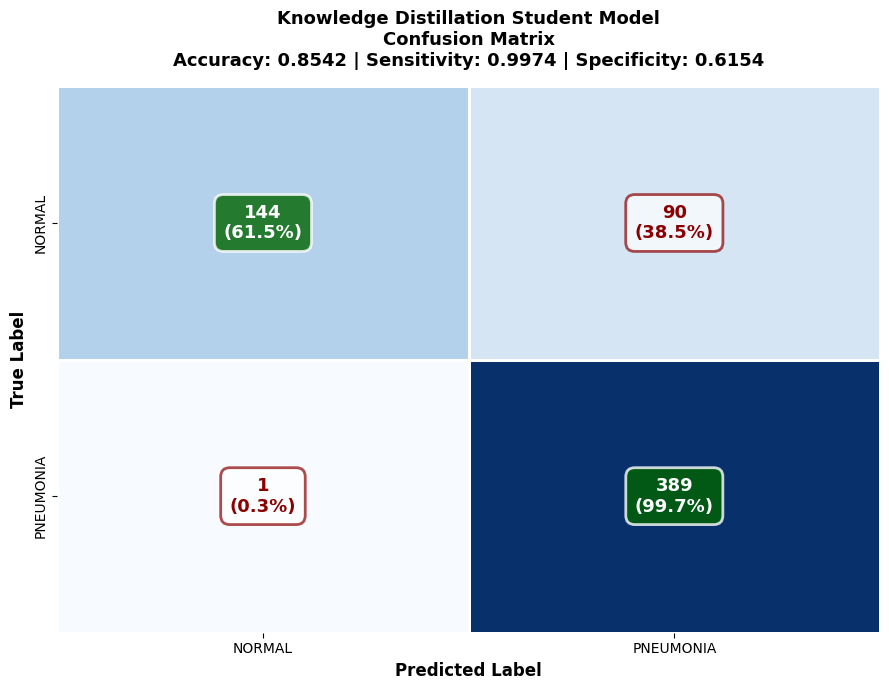

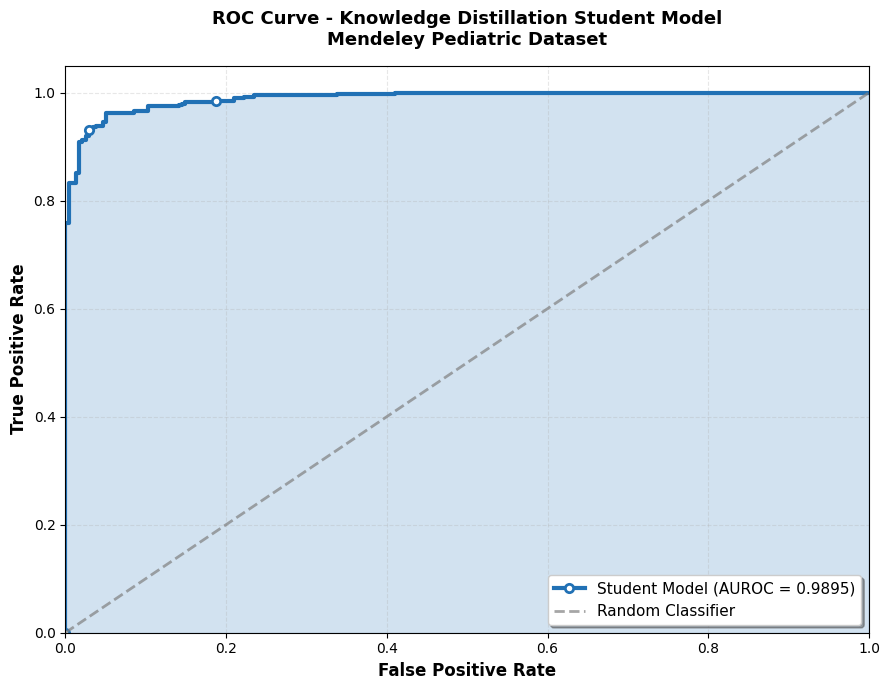

Visualizations complete


In [ ]:
# Confusion Matrix
plt.figure(figsize=(9, 7))

colors = ['#f7fbff', '#deebf7', '#c6dbef', '#6baed6', '#2171b5', '#08519c', '#08306b']
custom_cmap = sns.blend_palette(colors, as_cmap=True)

ax = sns.heatmap(cm, annot=False, fmt='d', cmap=custom_cmap,
                 xticklabels=class_names, yticklabels=class_names,
                 cbar=False, linewidths=2, linecolor='white')

for i in range(2):
    for j in range(2):
        value = cm[i, j]
        total = cm[i, :].sum()
        pct = value / total * 100 if total > 0 else 0

        if i == j:
            color = 'white'
            bbox_props = dict(boxstyle='round,pad=0.5', facecolor='darkgreen',
                            edgecolor='white', linewidth=2, alpha=0.8)
        else:
            color = 'darkred'
            bbox_props = dict(boxstyle='round,pad=0.5', facecolor='white',
                            edgecolor='darkred', linewidth=2, alpha=0.7)

        ax.text(j + 0.5, i + 0.5, f"{value}\n({pct:.1f}%)",
               ha='center', va='center', color=color,
               fontsize=13, fontweight='bold', bbox=bbox_props)

plt.title(f"Knowledge Distillation Student Model\nConfusion Matrix\n" +
          f"Accuracy: {accuracy:.4f} | Sensitivity: {sensitivity:.4f} | Specificity: {specificity:.4f}",
         fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Predicted Label", fontsize=12, fontweight='bold')
plt.ylabel("True Label", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(all_labels, all_predictions)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(9, 7))
plt.plot(fpr, tpr, color='#2171b5', linewidth=3,
         label=f'Student Model (AUROC = {roc_auc:.4f})', marker='o',
         markevery=20, markersize=6, markerfacecolor='white', markeredgewidth=2)
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=2,
         label='Random Classifier', alpha=0.7)
plt.fill_between(fpr, tpr, alpha=0.2, color='#2171b5')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
plt.title('ROC Curve - Knowledge Distillation Student Model\nMendeley Pediatric Dataset',
         fontsize=13, fontweight='bold', pad=15)
plt.legend(loc="lower right", fontsize=11, frameon=True, shadow=True)
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

print("Visualizations complete")

## **Knowledge Distillation Results & Visualisation**

In [ ]:
import pandas as pd

# Complete data including Nuclear Ensemble
results_data = {
    'Model': [
        'Nuclear Ensemble\n(Mendeley)',
        'Xception\n(Mendeley)',
        'EfficientNetB4\n(NIH)'
    ],

    # Original (Teacher)
    'Original Size (MB)': [300.74, 82.06, 208.32],
    'Original Accuracy (%)': [96.79, 96.96, 86.10],
    'Original Sensitivity (%)': [96.67, 96.92, 78.91],
    'Original Specificity (%)': [97.01, 97.01, 88.99],
    'Original AUROC': [0.9915, 0.9933, 0.8986],

    # INT8 Quantised
    'INT8 Size (MB)': [77.17, 21.61, 18.59],
    'INT8 Accuracy (%)': [95.99, 97.12, 80.94],
    'INT8 Sensitivity (%)': [96.67, 97.69, 72.66],
    'INT8 Specificity (%)': [95.30, 96.15, 84.28],
    'INT8 AUROC': [0.9925, 0.9934, 0.8563],

    # Knowledge Distillation Student (updated Nuclear Ensemble values)
    'KD Size (MB)': [49.06, 9.79, 9.80],
    'KD Accuracy (%)': [85.42, 91.51, 70.52],
    'KD Sensitivity (%)': [99.74, 97.95, 64.45],
    'KD Specificity (%)': [61.54, 80.77, 73.00],
    'KD AUROC': [0.9895, 0.9859, 0.7447],
}

df_results = pd.DataFrame(results_data)

# Display formatted table
print("\n" + "="*110)
print("KNOWLEDGE DISTILLATION: COMPARATIVE PERFORMANCE ANALYSIS")
print("="*110)
print(df_results.to_string(index=False))
print("="*110)

# # Save to CSV
# df_results.to_csv('KD_comparative_results.csv', index=False)
# print("\nTable saved to: KD_comparative_results.csv")


KNOWLEDGE DISTILLATION: COMPARATIVE PERFORMANCE ANALYSIS
                       Model  Original Size (MB)  Original Accuracy (%)  Original Sensitivity (%)  Original Specificity (%)  Original AUROC  INT8 Size (MB)  INT8 Accuracy (%)  INT8 Sensitivity (%)  INT8 Specificity (%)  INT8 AUROC  KD Size (MB)  KD Accuracy (%)  KD Sensitivity (%)  KD Specificity (%)  KD AUROC
Nuclear Ensemble\n(Mendeley)              300.74                  96.79                     96.67                     97.01          0.9915           77.17              95.99                 96.67                 95.30      0.9925         49.06            85.42               99.74               61.54    0.9895
        Xception\n(Mendeley)               82.06                  96.96                     96.92                     97.01          0.9933           21.61              97.12                 97.69                 96.15      0.9934          9.79            91.51               97.95               80.77    0.9859
      

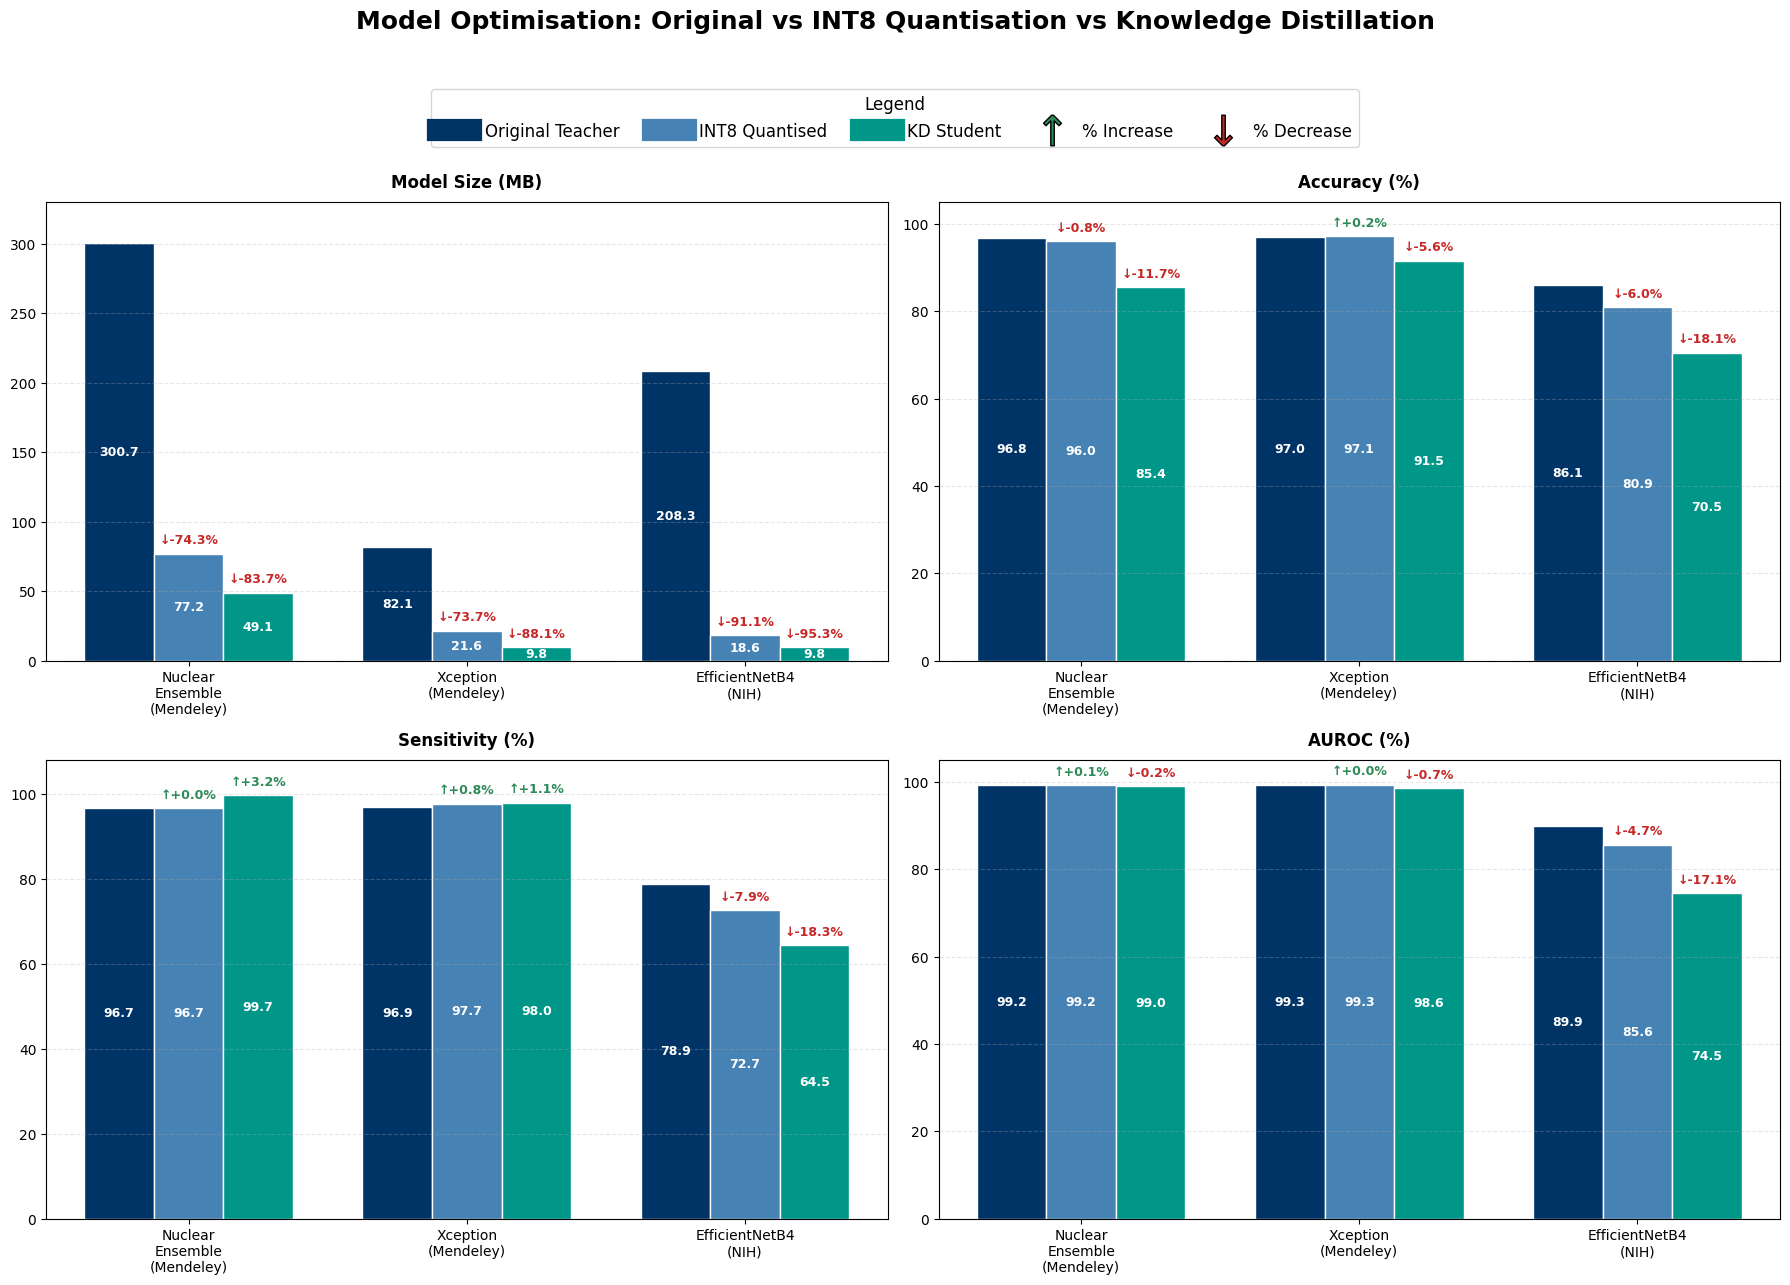

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import pandas as pd

# Data for 3 models
data = {
    'Model': ['Nuclear\nEnsemble\n(Mendeley)', 'Xception\n(Mendeley)', 'EfficientNetB4\n(NIH)'],

    # Original
    'Original_Size': [300.74, 82.06, 208.32],
    'Original_Acc': [96.79, 96.96, 86.10],
    'Original_Sens': [96.67, 96.92, 78.91],
    'Original_AUC': [99.15, 99.33, 89.86],

    # INT8 Quantised
    'INT8_Size': [77.17, 21.61, 18.59],
    'INT8_Acc': [95.99, 97.12, 80.94],
    'INT8_Sens': [96.67, 97.69, 72.66],
    'INT8_AUC': [99.25, 99.34, 85.63],

    # Knowledge Distillation
    'KD_Size': [49.06, 9.79, 9.80],
    'KD_Acc': [85.42, 91.51, 70.52],
    'KD_Sens': [99.74, 97.95, 64.45],
    'KD_AUC': [98.95, 98.59, 74.47],
}

df = pd.DataFrame(data)

# Compute % changes
for method in ['INT8', 'KD']:
    for metric in ['Size', 'Acc', 'Sens', 'AUC']:
        df[f'{method}_{metric}_Change'] = (
            (df[f'{method}_{metric}'] - df[f'Original_{metric}'])
            / df[f'Original_{metric}'] * 100
        )

# Figure setup
fig, axes = plt.subplots(2, 2, figsize=(18, 13))
axs = axes.ravel()
x = np.arange(len(df))
width = 0.25

# Professional palette
orig_col = '#003366'    # deep navy
int8_col = '#4682B4'    # steel blue
kd_col = '#009688'      # teal
inc_col = '#2E8B57'     # sea green
dec_col = '#C62828'     # red

def bar_triple(ax, orig_vals, int8_vals, kd_vals, title, ylim,
               int8_changes, kd_changes):
    # Bars
    b1 = ax.bar(x - width, orig_vals, width, label='Original Teacher',
                color=orig_col, edgecolor='white', linewidth=1)
    b2 = ax.bar(x, int8_vals, width, label='INT8 Quantised',
                color=int8_col, edgecolor='white', linewidth=1)
    b3 = ax.bar(x + width, kd_vals, width, label='KD Student',
                color=kd_col, edgecolor='white', linewidth=1)

    # Text inside bars
    for bars in [b1, b2, b3]:
        for bar in bars:
            h = bar.get_height()
            if h > 0:
                ax.text(bar.get_x() + bar.get_width()/2, h/2,
                        f'{h:.1f}', ha='center', va='center',
                        color='white', fontsize=9, fontweight='bold')

    # % change annotations
    for idx, (xi, ch) in enumerate(zip(x, int8_changes)):
        if pd.notna(ch):
            sign = '+' if ch >= 0 else ''
            col = inc_col if ch >= 0 else dec_col
            arrow = '↑' if ch >= 0 else '↓'
            ax.text(xi, int8_vals.iloc[idx] + ylim*0.015,
                    f'{arrow}{sign}{ch:.1f}%', ha='center', va='bottom',
                    color=col, fontsize=9, fontweight='bold')
    for idx, (xi, ch) in enumerate(zip(x + width, kd_changes)):
        if pd.notna(ch):
            sign = '+' if ch >= 0 else ''
            col = inc_col if ch >= 0 else dec_col
            arrow = '↑' if ch >= 0 else '↓'
            ax.text(xi, kd_vals.iloc[idx] + ylim*0.015,
                    f'{arrow}{sign}{ch:.1f}%', ha='center', va='bottom',
                    color=col, fontsize=9, fontweight='bold')

    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.set_ylim(0, ylim)
    ax.set_xticks(x)
    ax.set_xticklabels(df['Model'], fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.3)

# 1. Size
bar_triple(axs[0],
           df['Original_Size'], df['INT8_Size'], df['KD_Size'],
           'Model Size (MB)', 330,
           df['INT8_Size_Change'], df['KD_Size_Change'])

# 2. Accuracy
bar_triple(axs[1],
           df['Original_Acc'], df['INT8_Acc'], df['KD_Acc'],
           'Accuracy (%)', 105,
           df['INT8_Acc_Change'], df['KD_Acc_Change'])

# 3. Sensitivity
bar_triple(axs[2],
           df['Original_Sens'], df['INT8_Sens'], df['KD_Sens'],
           'Sensitivity (%)', 108,
           df['INT8_Sens_Change'], df['KD_Sens_Change'])

# 4. AUROC
bar_triple(axs[3],
           df['Original_AUC'], df['INT8_AUC'], df['KD_AUC'],
           'AUROC (%)', 105,
           df['INT8_AUC_Change'], df['KD_AUC_Change'])

# Main title (leave room for legend underneath)
fig.suptitle('Model Optimisation: Original vs INT8 Quantisation vs Knowledge Distillation',
             fontsize=18, fontweight='bold', y=0.985)

# Unified legend (top centre, placed under main title)
handles = [
    Line2D([0], [0], color=orig_col, lw=16, marker='s', markersize=12),
    Line2D([0], [0], color=int8_col, lw=16, marker='s', markersize=12),
    Line2D([0], [0], color=kd_col, lw=16, marker='s', markersize=12),
    Line2D([0], [0], marker='$↑$', color='none', markerfacecolor=inc_col,
           markersize=22, linestyle='None'),
    Line2D([0], [0], marker='$↓$', color='none', markerfacecolor=dec_col,
           markersize=22, linestyle='None'),
]
labels = ['Original Teacher', 'INT8 Quantised', 'KD Student', '% Increase', '% Decrease']

# Place legend under the main title; bbox_to_anchor y chosen to sit neatly below the title
fig.legend(handles, labels, loc='upper center', ncol=5, fontsize=12,
           frameon=True, fancybox=True, shadow=False, title='Legend', title_fontsize=12,
           bbox_to_anchor=(0.5, 0.93))

# Adjust layout to leave space for title + legend at top
plt.tight_layout(rect=[0, 0, 1, 0.90])

# Save at very high quality
fig.savefig('KD_optimisation_comparison.png', dpi=1200, bbox_inches='tight', facecolor='white')

# Display the figure
plt.show()

### **Ensemble Validation Tuned Weights**

In [ ]:
# ======================================================================
# Nuclear Ensemble: weights re-optimised on the validation subset, then re-evaluated
# Section to APPEND at the end of the Nuclear Ensemble notebook (do not edit or delete earlier cells).
# Nothing is retrained. Existing files are not overwritten; new outputs go to a new folder.
# Run on a fresh runtime. Takes roughly 10 to 20 minutes (INT8 predictions are image by image).
# ======================================================================
import os, sys, subprocess
try:
    import optuna
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'optuna']); import optuna
import glob, numpy as np, tensorflow as tf
from scipy.stats import binomtest
from sklearn.metrics import roc_auc_score, confusion_matrix, f1_score
from tensorflow.keras.preprocessing.image import ImageDataGenerator

BASE = '/content/drive/MyDrive/chest_xray'
TRAIN, TEST = f'{BASE}/train', f'{BASE}/test'
QDIR = f'{BASE}/PTQ_Quantized_Ensemble'                 # INT8 base models (the copy that reproduces the paper's Xception INT8 result)
OUT = f'{BASE}/ensemble_validation_tuned'; os.makedirs(OUT, exist_ok=True)
PRE = [tf.keras.applications.resnet.preprocess_input, tf.keras.applications.densenet.preprocess_input,
       tf.keras.applications.inception_v3.preprocess_input, tf.keras.applications.xception.preprocess_input,
       tf.keras.applications.mobilenet_v2.preprocess_input]
NAMES = ['ResNet50', 'DenseNet121', 'InceptionV3', 'Xception', 'MobileNetV2']
BLEND_META, BLEND_WEIGHTED = 0.6, 0.4                  # constants used in the original notebook

models = [tf.keras.models.load_model(f'{BASE}/base_model_{i}.keras', compile=False) for i in range(5)]
meta = tf.keras.models.load_model(f'{BASE}/nuclear_ensemble_meta_learner.keras', compile=False)
saved_w = [f for f in glob.glob(f'{BASE}/*.npy') if 'optimal_weights' in f.lower() and 'student' not in f.lower()][0]
w_saved = np.load(saved_w); print('saved weights (tuned on the first 400 test images):', np.round(w_saved, 4))

saved weights (tuned on the first 400 test images): [0.3599 0.3283 0.0086 0.3    0.0031]


In [ ]:
# predictions of the original (Keras) base models
def collect_keras(path, subset=None):
    feats = []
    for m, pf in zip(models, PRE):
        h, w = m.input_shape[1:3]
        gen = ImageDataGenerator(preprocessing_function=pf, validation_split=0.2 if subset else 0.0)
        kw = dict(subset=subset, seed=123) if subset else {}
        it = gen.flow_from_directory(path, target_size=(h, w), class_mode='categorical',
                                     batch_size=32, shuffle=False, **kw)
        feats.append(m.predict(it, verbose=0)); y = it.classes
    return np.stack(feats, axis=1), y                 # [N, 5, 2], [N]
Xv, yv = collect_keras(TRAIN, 'validation'); Xt, yt = collect_keras(TEST)
print('validation images', len(yv), '| test images', len(yt))

Found 1045 images belonging to 2 classes.
Found 1045 images belonging to 2 classes.
Found 1045 images belonging to 2 classes.
Found 1045 images belonging to 2 classes.
Found 1045 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
validation images 1045 | test images 624


In [ ]:
# predictions of the INT8 base models (float input and output)
def collect_tflite():
    feats = []; total = 0
    for i, pf in enumerate(PRE):
        f = f'{QDIR}/base_model_{i}_int8.tflite'; assert os.path.exists(f), f'missing {f}'
        total += os.path.getsize(f) / 1024**2
        it = tf.lite.Interpreter(model_path=f); it.allocate_tensors()
        d_in, d_out = it.get_input_details()[0], it.get_output_details()[0]
        h, w = [int(v) for v in d_in['shape'][1:3]]
        gen = ImageDataGenerator(preprocessing_function=pf).flow_from_directory(
            TEST, target_size=(h, w), class_mode='categorical', batch_size=1, shuffle=False)
        p = []
        for _ in range(len(gen)):
            it.set_tensor(d_in['index'], next(gen)[0].astype(np.float32)); it.invoke()
            p.append(it.get_tensor(d_out['index'])[0])
        feats.append(np.array(p)); print('  INT8', NAMES[i], 'done')
    print('total INT8 base-model size %.2f MB' % total)
    return np.stack(feats, axis=1)
Xq = collect_tflite()

#  helpers
wavg = lambda X, w: np.tensordot(w, X, axes=([0], [1]))
blend = lambda X, w: BLEND_META * meta.predict(X, verbose=0) + BLEND_WEIGHTED * wavg(X, w)
def metrics(y, p):
    pred = p.argmax(1); tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    se, sp = tp / (tp + fn), tn / (tn + fp)
    return dict(tn=tn, fp=fp, fn=fn, tp=tp, acc=(tp + tn) / len(y), sens=se, spec=sp, bal=(se + sp) / 2,
                auroc=roc_auc_score(y, p[:, 1]))
def show(name, p):
    m = metrics(yt, p)
    print(f"{name:44s} TN {m['tn']} FP {m['fp']} FN {m['fn']} TP {m['tp']} | acc {m['acc']:.4f} sens {m['sens']:.4f} "
          f"spec {m['spec']:.4f} bal {m['bal']:.4f} AUROC {m['auroc']:.4f}")

# 1. validation-tuned weights (validation images only)
def objective(trial):
    w = np.array([trial.suggest_float(f'w{i}', 0, 1) for i in range(5)]); w /= w.sum()
    return (wavg(Xv, w).argmax(1) == yv).mean()
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
optuna.logging.set_verbosity(optuna.logging.WARNING)
study.optimize(objective, n_trials=100)
w_val = np.array([study.best_params[f'w{i}'] for i in range(5)]); w_val /= w_val.sum()
np.save(f'{OUT}/ensemble_weights_validation_tuned.npy', w_val)
print('\nvalidation-tuned weights:', dict(zip(NAMES, np.round(w_val, 4))), '| validation accuracy', round(study.best_value, 4))

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Found 624 images belonging to 2 classes.
  INT8 ResNet50 done
Found 624 images belonging to 2 classes.
  INT8 DenseNet121 done
Found 624 images belonging to 2 classes.
  INT8 InceptionV3 done
Found 624 images belonging to 2 classes.
  INT8 Xception done
Found 624 images belonging to 2 classes.


[I 2026-10-22 23:01:17,517] A new study created in memory with name: no-name-200eae25-3b18-426d-a2d7-d088163e6524


  INT8 MobileNetV2 done
total INT8 base-model size 77.17 MB

validation-tuned weights: {'ResNet50': np.float64(0.011), 'DenseNet121': np.float64(0.0039), 'InceptionV3': np.float64(0.3538), 'Xception': np.float64(0.5113), 'MobileNetV2': np.float64(0.12)} | validation accuracy 0.9569


In [ ]:
# 2. evaluation on the 624 test images
print('\n=== ORIGINAL (Keras) ensemble, blend = 0.6 x meta-learner + 0.4 x weighted base models ===')
show('saved weights (reproduces the paper: 96.79 / 0.9915)', blend(Xt, w_saved))
show('equal weights', blend(Xt, np.ones(5) / 5))
show('validation-tuned weights  [PRIMARY]', blend(Xt, w_val))
print('\n=== INT8 ensemble (same meta-learner, same blend) ===')
show('INT8, validation-tuned weights  [PRIMARY]', blend(Xq, w_val))
show('INT8, saved weights', blend(Xq, w_saved))
# archived INT8 method: performance weights from each INT8 model's own TEST accuracy and F1 (no meta-learner)
perf = np.array([(metrics(yt, Xq[:, i])['acc'] + f1_score(yt, Xq[:, i].argmax(1))) / 2 for i in range(5)]); perf /= perf.sum()
show('INT8, archived performance weights (no meta; 95.99 / 0.9925)', wavg(Xq, perf))
print('archived performance weights:', dict(zip(NAMES, np.round(perf, 4))))

# 3. paired comparison, original against INT8, primary configuration
po, pq = blend(Xt, w_val), blend(Xq, w_val)
ok_o, ok_q = po.argmax(1) == yt, pq.argmax(1) == yt
b, c = int((ok_o & ~ok_q).sum()), int((~ok_o & ok_q).sum())
print(f'\ndiscordant pairs: original right/INT8 wrong {b}, original wrong/INT8 right {c}; McNemar exact p = '
      f'{binomtest(b, b + c, 0.5).pvalue:.4f}' if b + c else '\nno discordant pairs')
rng = np.random.default_rng(0); d = {'accuracy': [], 'balanced accuracy': [], 'AUROC': []}
for _ in range(5000):
    idx = rng.integers(0, len(yt), len(yt)); yy = yt[idx]
    if yy.min() == yy.max(): continue
    mo, mq = metrics(yy, po[idx]), metrics(yy, pq[idx])
    d['accuracy'].append(mq['acc'] - mo['acc']); d['balanced accuracy'].append(mq['bal'] - mo['bal']); d['AUROC'].append(mq['auroc'] - mo['auroc'])
for k, v in d.items():
    lo, hi = np.percentile(v, [2.5, 97.5]); print(f'  INT8 minus original, {k}: {np.mean(v):+.4f} (95% CI {lo:+.4f} to {hi:+.4f})')

np.savez(f'{OUT}/ensemble_predictions.npz', yt=yt, yv=yv, Xt=Xt, Xv=Xv, Xq=Xq, w_saved=w_saved, w_val=w_val, perf=perf)
print('\nsaved to', OUT)


=== ORIGINAL (Keras) ensemble, blend = 0.6 x meta-learner + 0.4 x weighted base models ===
saved weights (reproduces the paper: 96.79 / 0.9915) TN 230 FP 4 FN 31 TP 359 | acc 0.9439 sens 0.9205 spec 0.9829 bal 0.9517 AUROC 0.9922
equal weights                                TN 230 FP 4 FN 28 TP 362 | acc 0.9487 sens 0.9282 spec 0.9829 bal 0.9556 AUROC 0.9921
validation-tuned weights  [PRIMARY]          TN 230 FP 4 FN 27 TP 363 | acc 0.9503 sens 0.9308 spec 0.9829 bal 0.9568 AUROC 0.9923

=== INT8 ensemble (same meta-learner, same blend) ===
INT8, validation-tuned weights  [PRIMARY]    TN 226 FP 8 FN 11 TP 379 | acc 0.9696 sens 0.9718 spec 0.9658 bal 0.9688 AUROC 0.9932
INT8, saved weights                          TN 226 FP 8 FN 12 TP 378 | acc 0.9679 sens 0.9692 spec 0.9658 bal 0.9675 AUROC 0.9936
INT8, archived performance weights (no meta; 95.99 / 0.9925) TN 218 FP 16 FN 9 TP 381 | acc 0.9599 sens 0.9769 spec 0.9316 bal 0.9543 AUROC 0.9925
archived performance weights: {'ResNet50': 